<a href="https://colab.research.google.com/github/aimanmumtazofficial/CodeAlpha_Car_Price_Prediction_with_Machine_Learning/blob/main/House_price_pridiction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Libraries :

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")

Load DAtaset.

In [ ]:
data = pd.read_csv('/content/train (1).csv')
data.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Basic Info & Summary.

In [ ]:
print(f"Data Shape: {data.shape}")

Data Shape: (1460, 81)


In [ ]:
num_features = data.select_dtypes(include=[np.number]).columns.tolist()
cat_features = data.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical Features ({len(num_features)}):")
print(num_features)

print("-"*180)

print(f"Categorical Features ({len(cat_features)}):")
print(cat_features)


Numerical Features (38):
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Categorical Features (43):
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual

Missing Values.

In [ ]:
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\Missing values per column (sorted)")
if missing.empty:
  print("No missing values found!")
else:
  print(missing.to_string())

\Missing values per column (sorted)
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1


Visulization missing values.

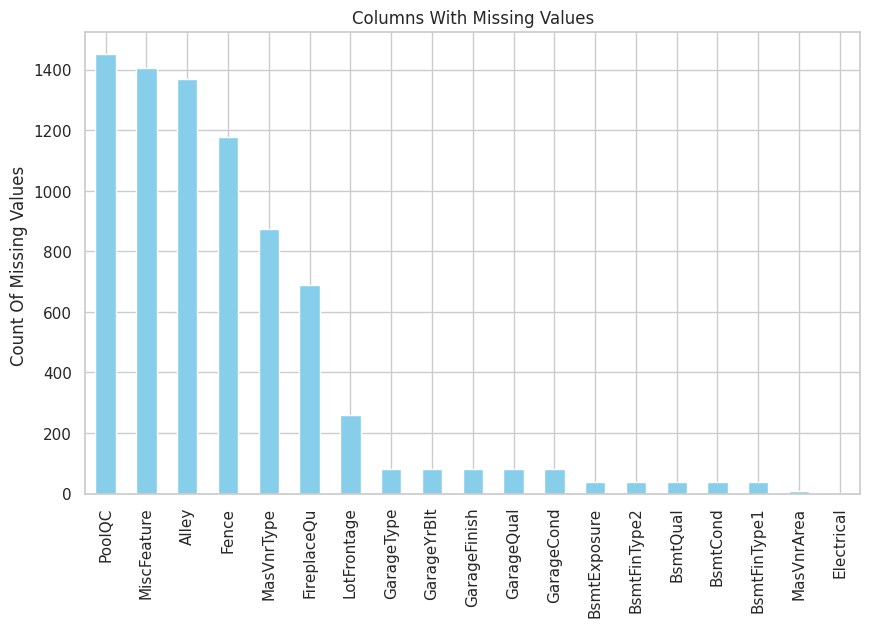

In [ ]:
plt.figure(figsize=(10,6))
missing.plot(kind='bar', color='skyblue')
plt.title('Columns With Missing Values')
plt.ylabel('Count Of Missing Values ')
plt.show()



#This bar chart shows how many missing values each column in the dataset contains.
#Columns like PoolQC, MiscFeature, Alley, and Fence have the highest number of missing entries, meaning most houses don’t report these features.
#On the other hand, features like Electrical and MasVnrArea have very few or almost no missing values.
#This visualization helps identify which columns need imputation, dropping, or special handling in data cleaning.

In [ ]:
print("\nData Types by Columns:")
print(data.dtypes.to_string())


Data Types by Columns:
Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1         int64
BsmtFinType2      object
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
H

Univariate Analysis.(Numerical Variables).

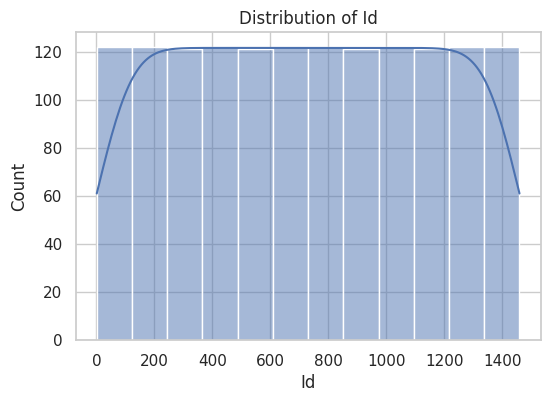

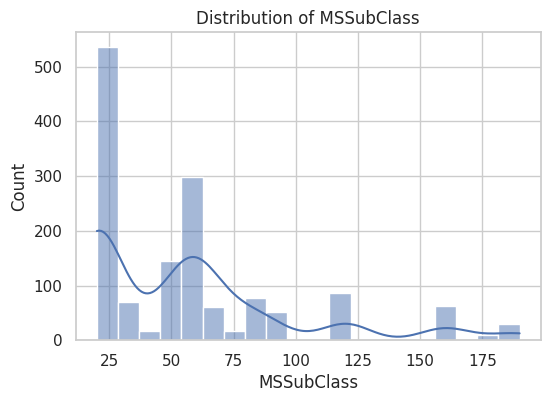

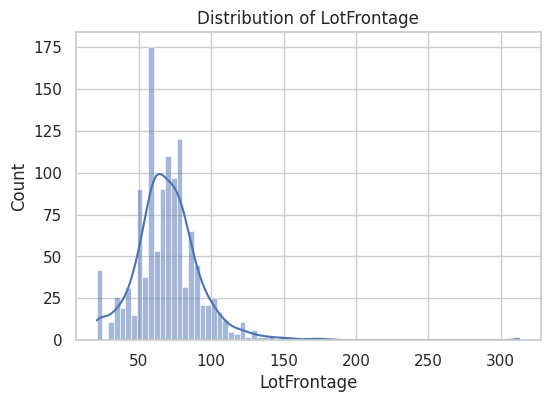

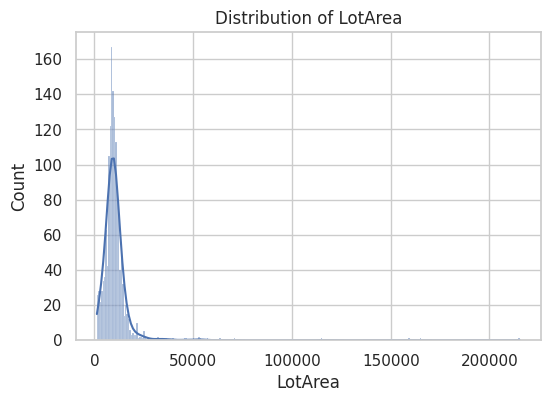

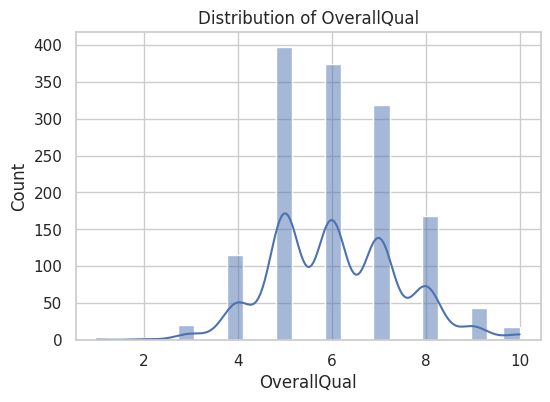

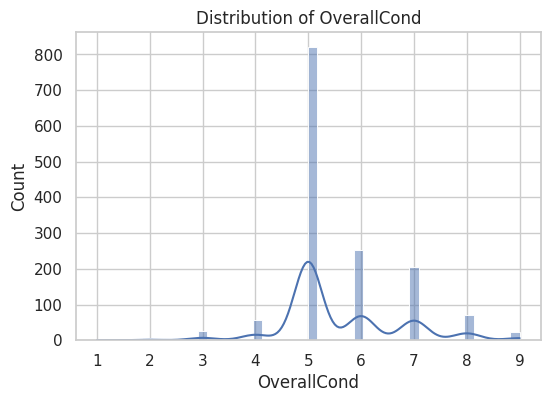

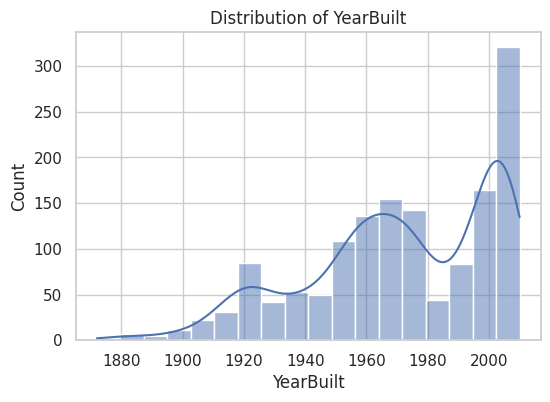

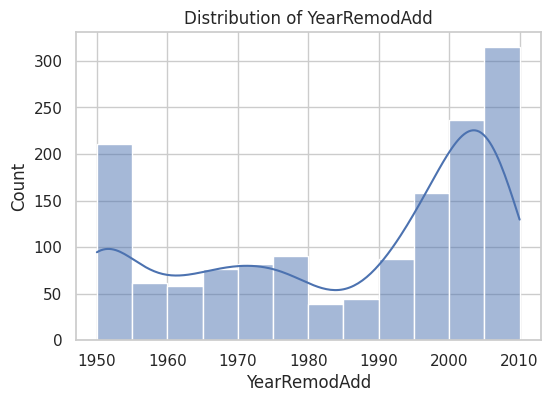

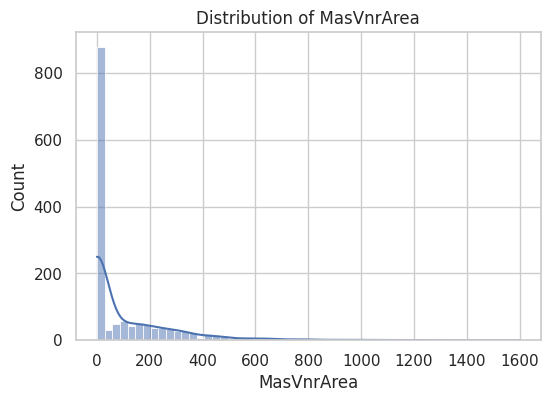

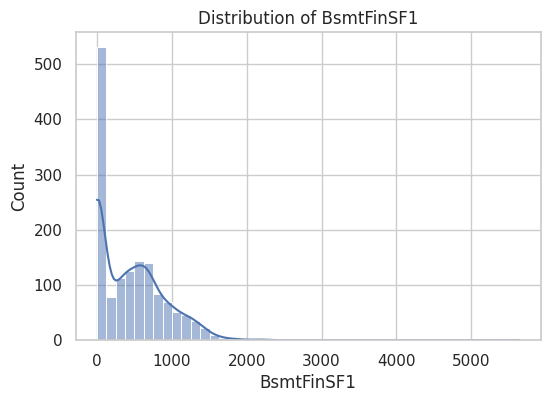

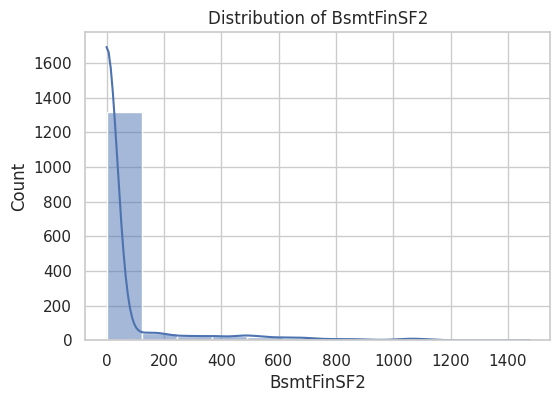

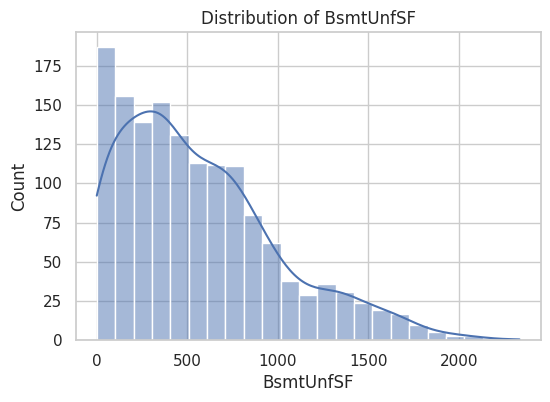

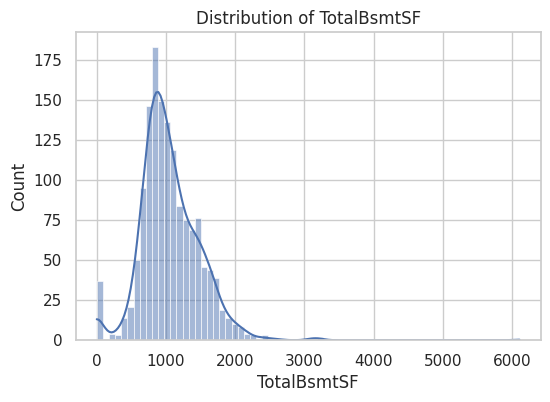

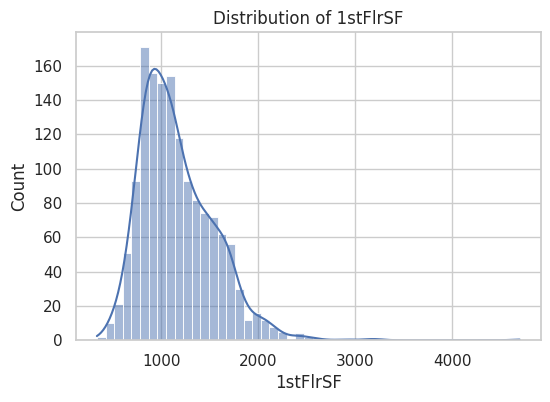

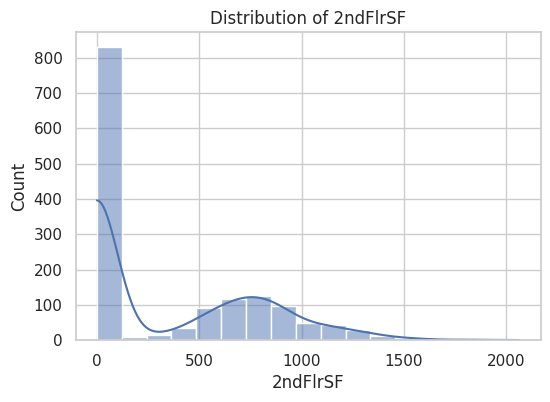

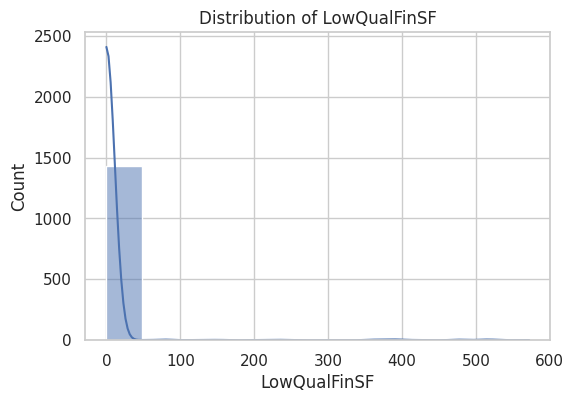

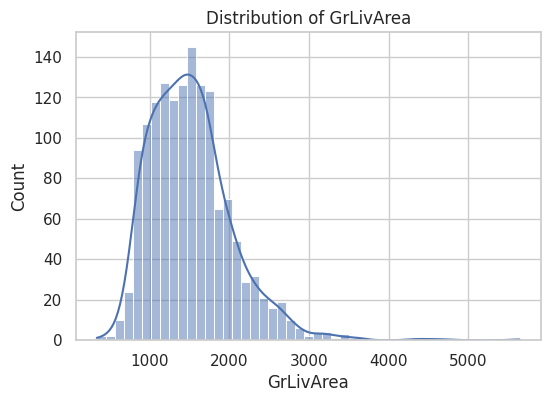

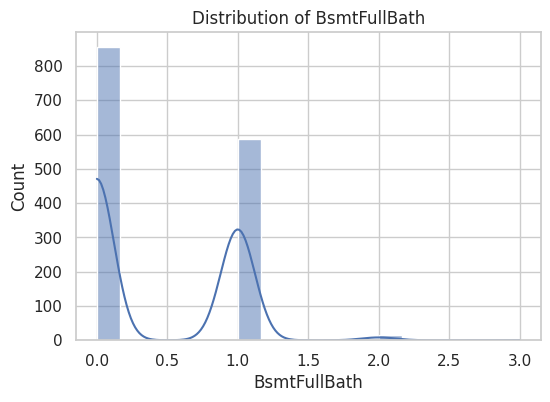

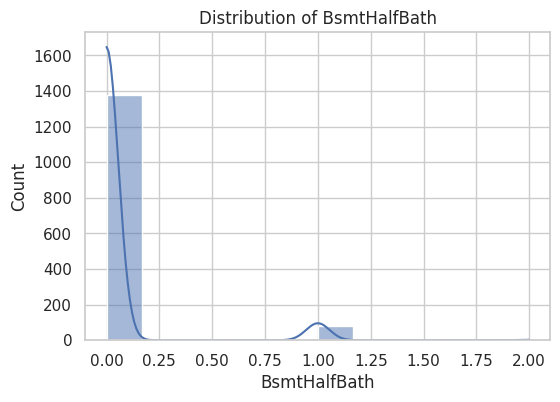

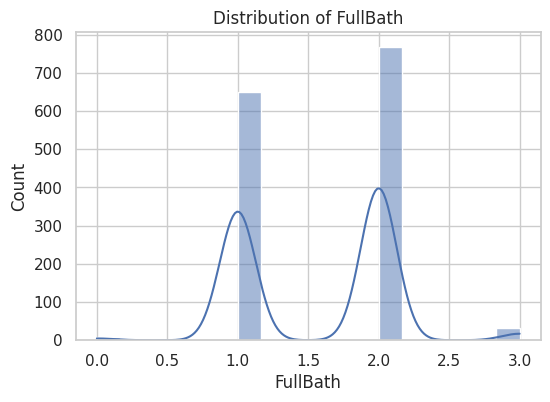

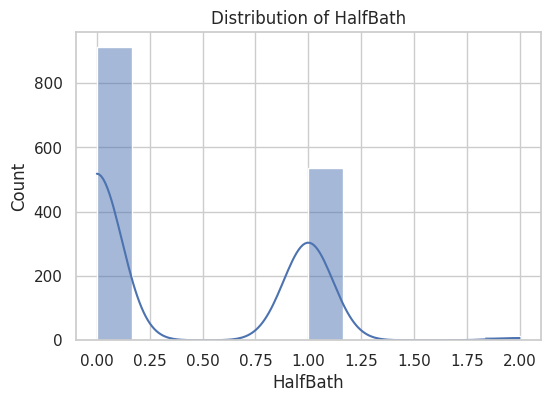

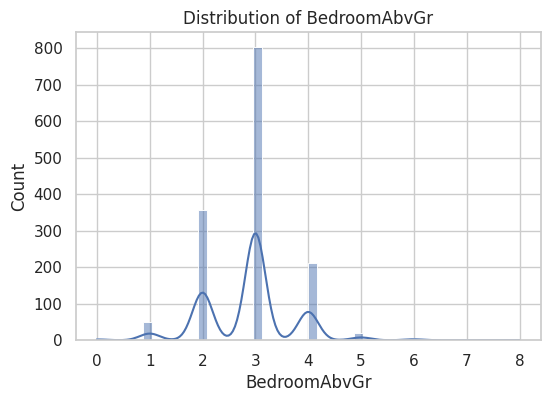

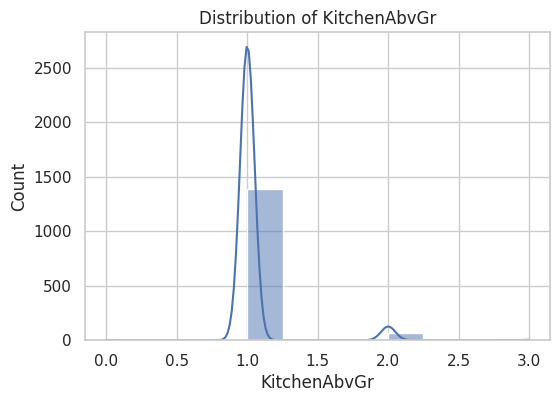

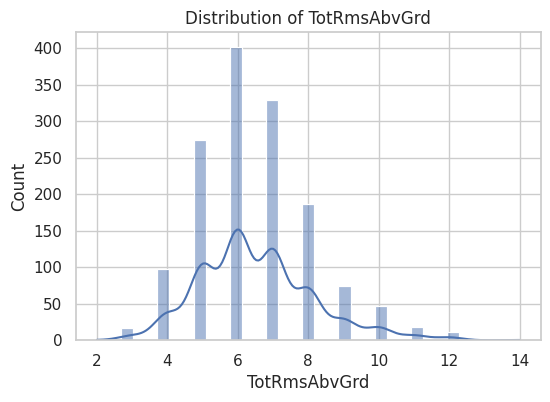

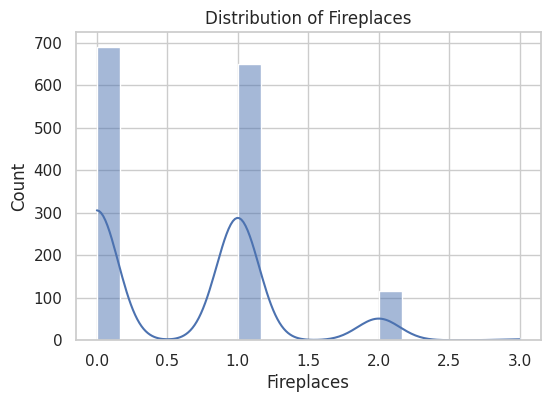

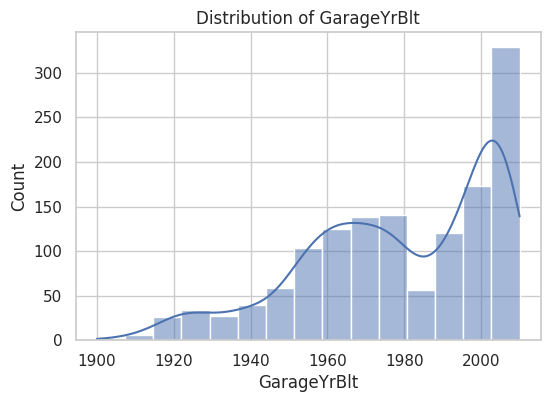

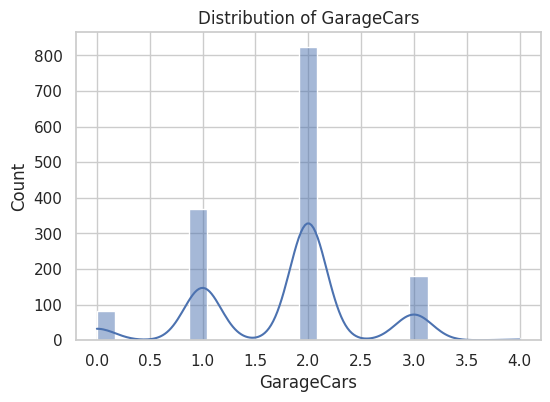

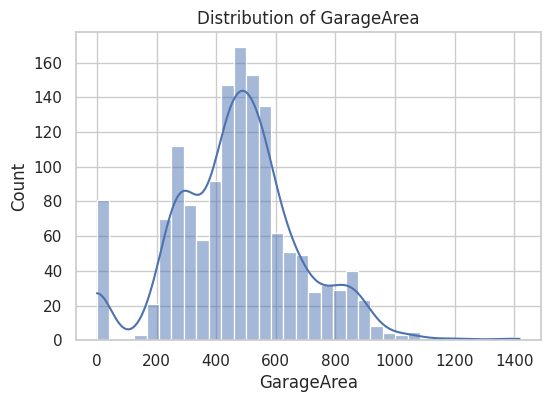

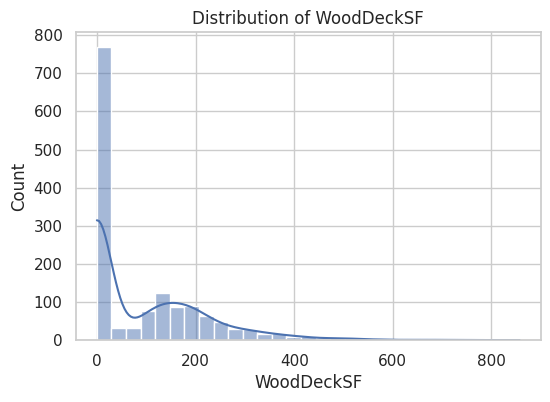

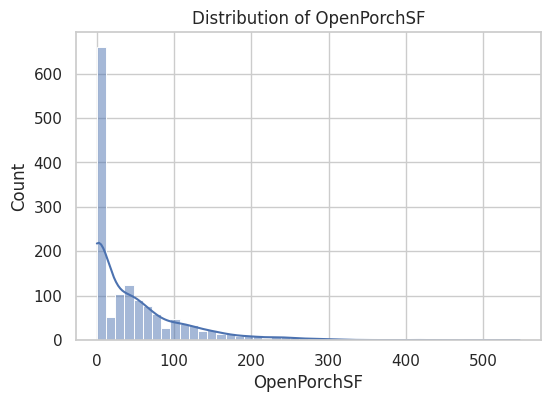

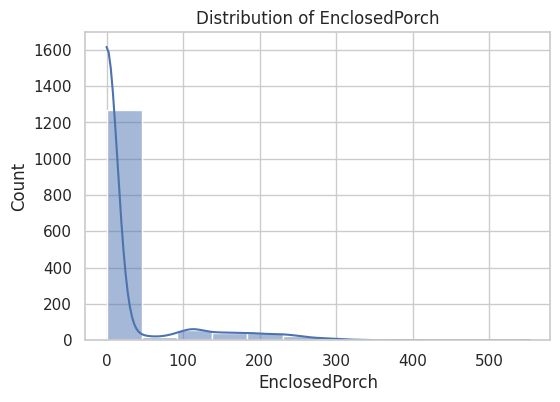

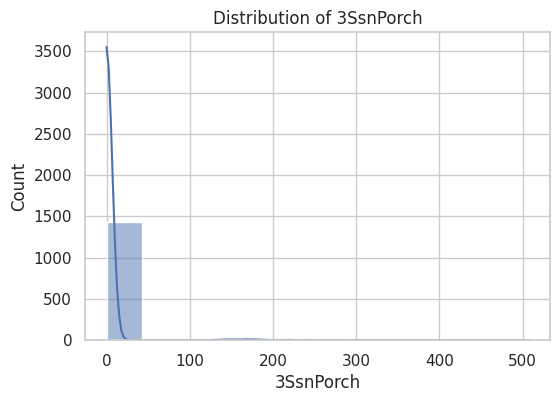

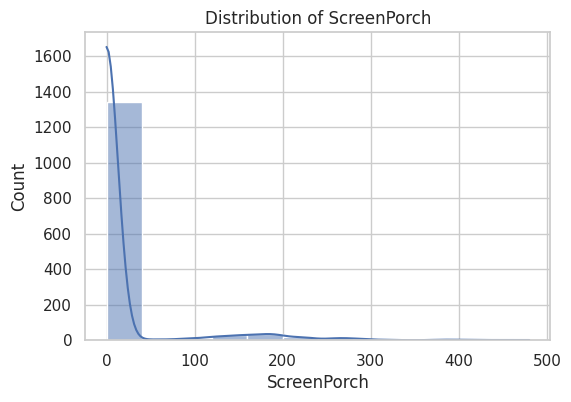

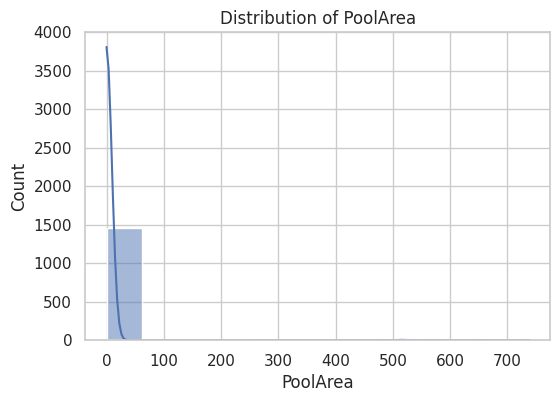

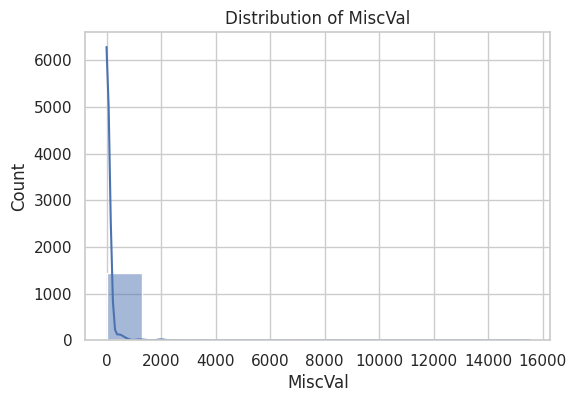

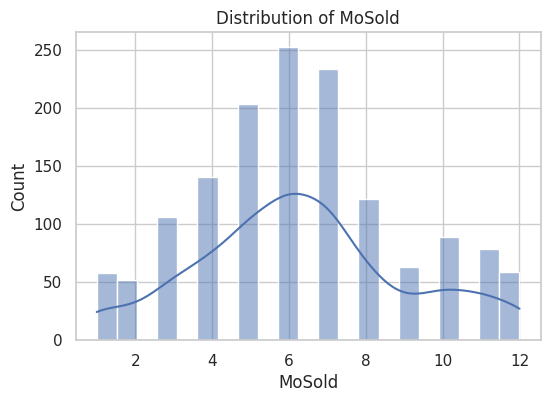

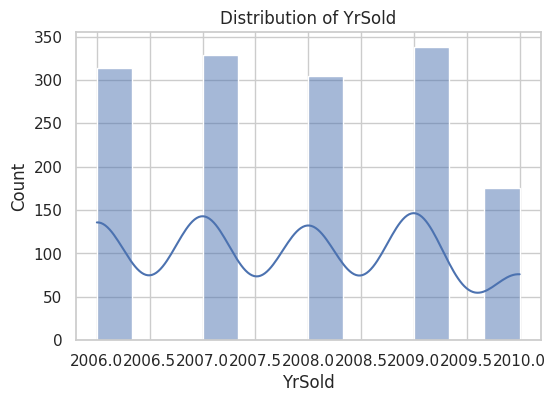

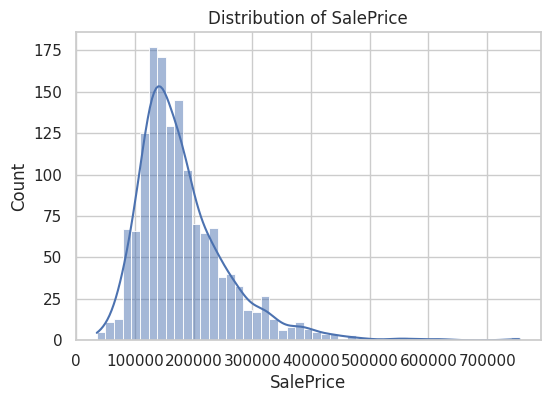

In [ ]:


#This loop plots the distribution of every numerical feature
#For each column, it creates a histogram with a Kde curve to show the shape of the data whether it is normal, skewed, or has outliers.
#These plots help you understand the spread, central tendency, and skewness of each numerical variable.
#This step is important for deciding transformations or scaling in preprocessing.

Univariate Categorical Analysis.

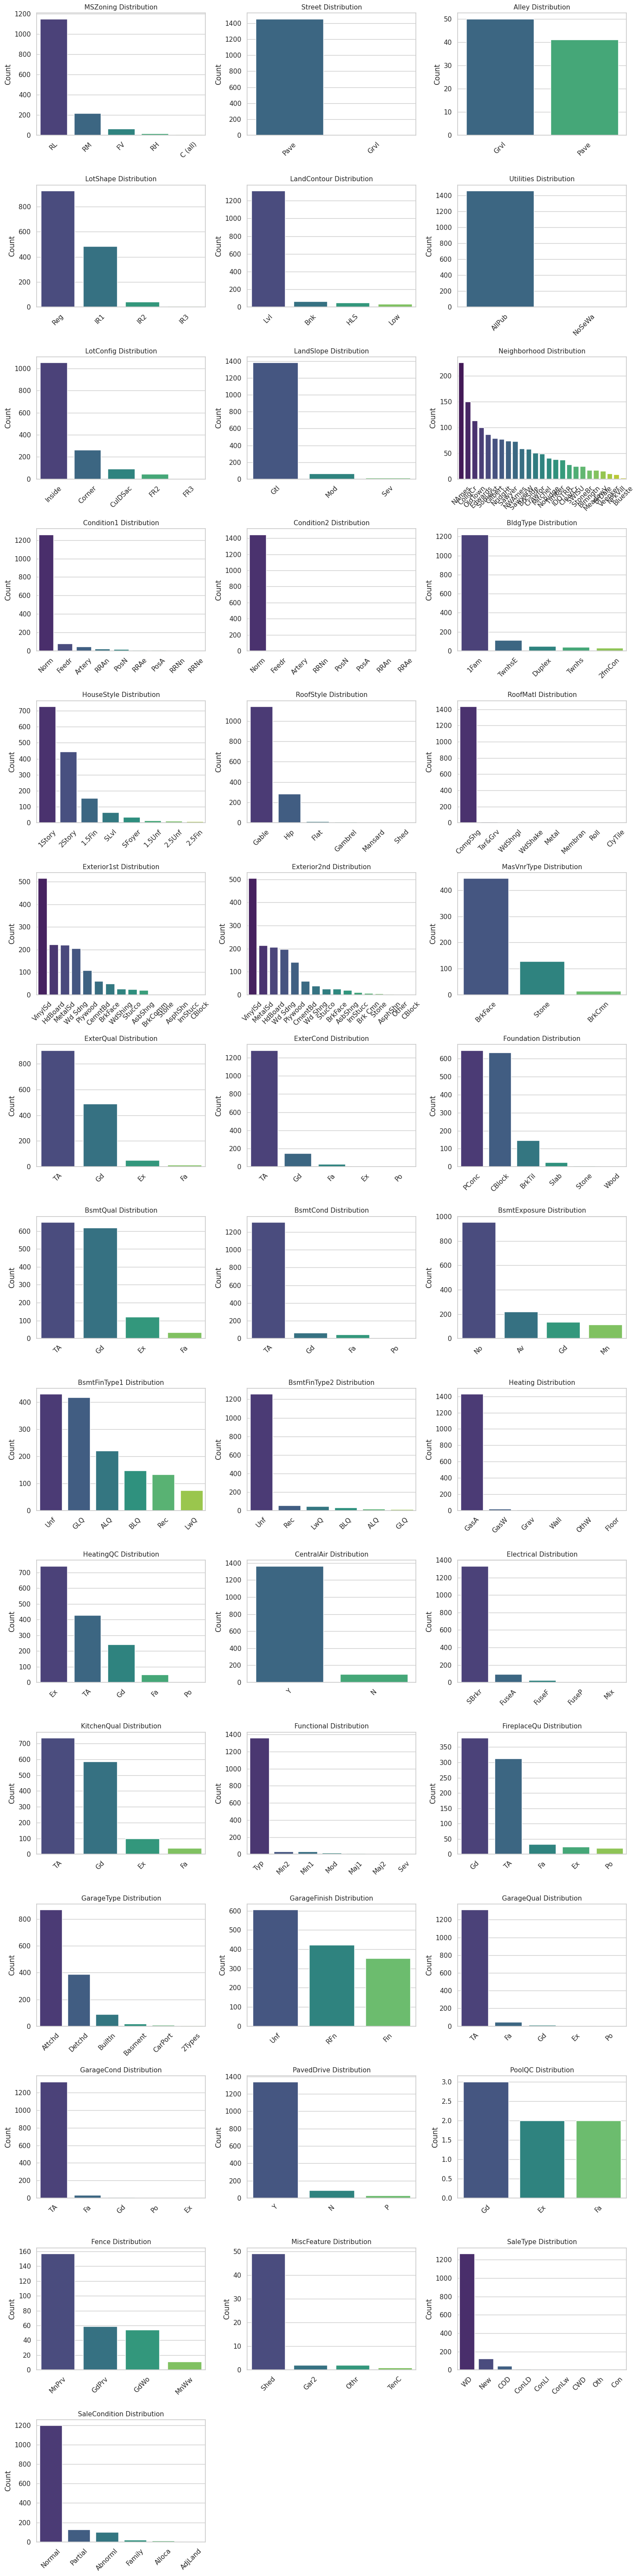

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(cat_features) / n_cols))

plt.figure(figsize=(n_cols*5, n_rows*4))

for idx, col in enumerate(cat_features, 1):
  plt.subplot(n_rows, n_cols, idx)
  sns.countplot(data=data, x=col, order=data[col].value_counts().index, palette="viridis")
  plt.title(f"{col} Distribution", fontsize=11)
  plt.xticks(rotation=45)
  plt.xlabel("")
  plt.ylabel("Count")

plt.tight_layout()
plt.show()


#This code creates multiple count plots to show the distribution of each categorical feature.
#It arranges the plots in a grid so all categories can be visualized together.
#Each count plot displays how frequently each category appears in the dataset, helping you identify dominant, rare, or imbalanced categories.
#This visualization is useful for understanding encoding needs and potential preprocessing steps.

Bivariate Analysis (DIY)

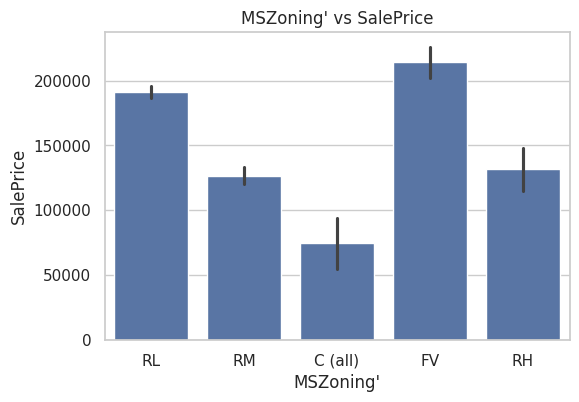

In [ ]:
#Bivariate analysi numerical vs categorical column.
plt.figure(figsize=(6,4))
sns.barplot(x='MSZoning', y='SalePrice', data = data)
plt.title("MSZoning' vs SalePrice")
plt.xlabel("MSZoning'")
plt.ylabel("SalePrice")
plt.show()

#This bar plot shows the relationship between the categorical feature MSZoning and the numerical target SalePrice.
#It displays the average sale price for each zoning category, helping you see which zones generally have higher-priced houses. Such plots highlight how categorical variables influence the target.
#This is useful for feature understanding and model interpretation.


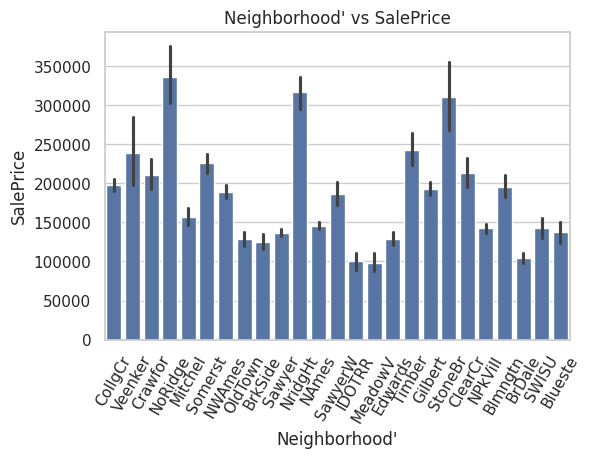

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(x='Neighborhood', y='SalePrice', data = data)
plt.title("Neighborhood' vs SalePrice")
plt.xlabel("Neighborhood'")
plt.ylabel("SalePrice")
plt.xticks(rotation=60)
plt.show()

#This bar plot compares the average SalePrice across different Neighborhoods. It shows how location affects house prices, with some neighborhoods having much higher average prices than others.
#Rotating the labels helps make all neighborhood names readable. This visualization is useful for understanding how strongly location influences housing value.

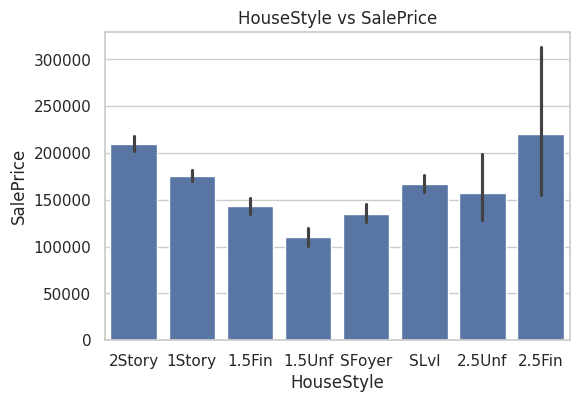

In [ ]:
plt.figure(figsize=(6,4))
sns.barplot(x='HouseStyle', y='SalePrice', data=data)
plt.title("HouseStyle vs SalePrice")
plt.xlabel("HouseStyle")
plt.ylabel("SalePrice")
plt.show()

#This bar plot shows the average SalePrice for each HouseStyle category. It helps you understand which house styles tend to be more expensive or lower priced.
#By comparing these averages, you can see how architectural style influences property value. This is useful for identifying important categorical features in the dataset.

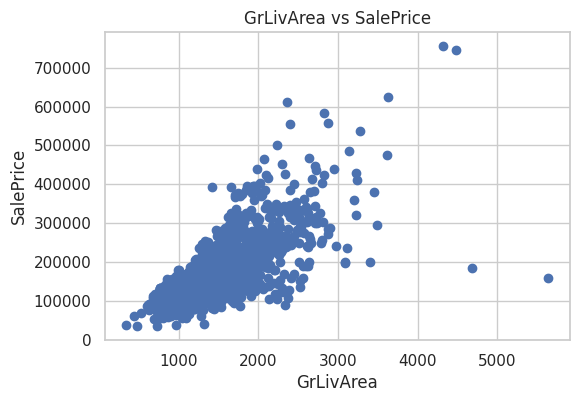

In [ ]:
#Bivariate analysis numerical vs numerical columns.
plt.figure(figsize=(6,4))
plt.scatter(x='GrLivArea', y='SalePrice', data=data)
plt.title("GrLivArea vs SalePrice")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.show()

#This scatter plot shows the relationship between GrLivArea above ground living area and SalePrice. The upward trend indicates that larger living areas generally lead to higher house prices
# and also spot potential outliers points far from the trend line. This visualization helps understand linearity and how strongly the feature influences the target.

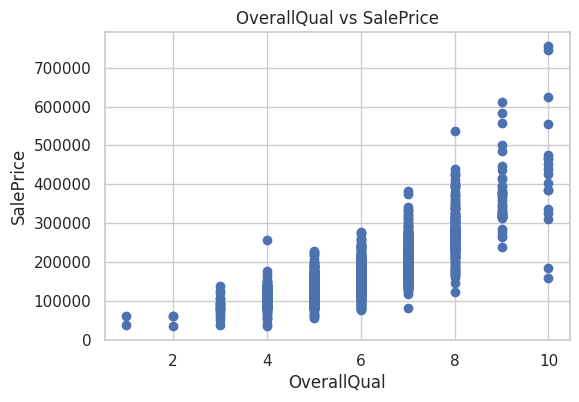

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(x='OverallQual', y='SalePrice', data=data)
plt.title("OverallQual vs SalePrice")
plt.xlabel("OverallQual")
plt.ylabel("SalePrice")
plt.show()

#This scatter plot shows the relationship between OverallQual overall material and finish quality and SalePrice.
#There is a clear upward pattern, meaning houses with higher quality ratings tend to have higher prices.
#The points form distinct levels because OverallQual is a discrete rating from 1 to 10. This visualization helps confirm that OverallQual is one of the strongest predictors of SalePrice.

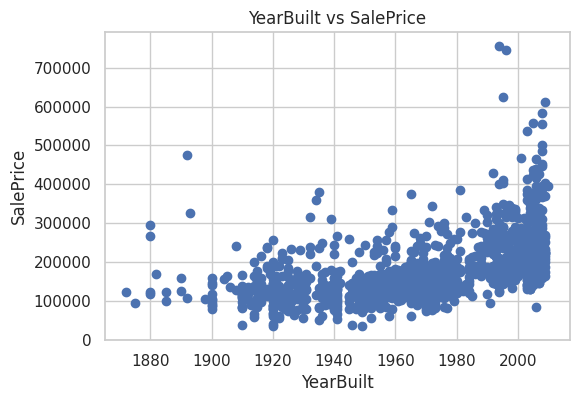

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(x='YearBuilt', y='SalePrice', data=data)
plt.title("YearBuilt vs SalePrice")
plt.xlabel("YearBuilt")
plt.ylabel("SalePrice")
plt.show()

#This scatter plot shows the relationship between YearBuilt and SalePrice. The trend suggests that newer houses generally sell for higher prices compared to older ones.
#The spread of points also reveals that price variation increases for recently built homes. This visualization helps understand how the age of a house influences its market value.

Handling Missing Values.

In [ ]:
#Categorical Features  where missing means "None"
none_fill_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence',
                  'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
                  'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
                  'MasVnrType',"FireplaceQu"]
for col in none_fill_cols:
  data[col] = data[col].fillna("None")

In [ ]:
#Numerical columns where missing means "0"
zero_fill_cols = [ 'GarageYrBlt', 'MasVnrArea']
for col in zero_fill_cols:
  data[col] = data[col].fillna(0)

In [ ]:
# LotFrontage — use median per neighborhood
data['LotFrontage'] = data.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
# Electrical — only 1 missing, fill with mode
data['Electrical'] = data['Electrical'].fillna(data['Electrical'].mode()[0])

In [ ]:
print("Remaining missing values:\n", data.isnull().sum()[data.isnull().sum() > 0])

Remaining missing values:
 Series([], dtype: int64)


Outlier Check (Boxplots) - Numerical Variables

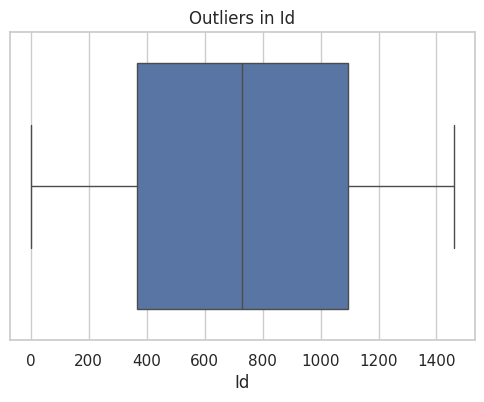

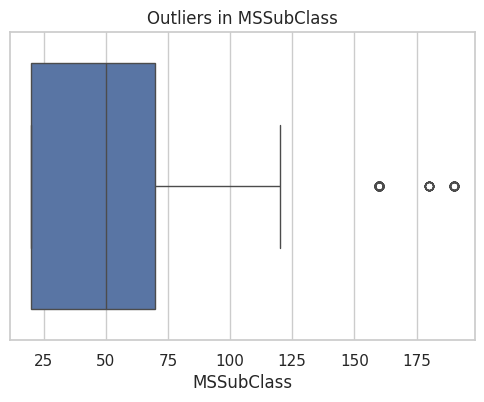

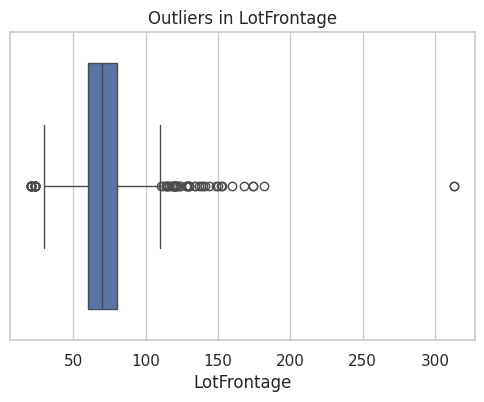

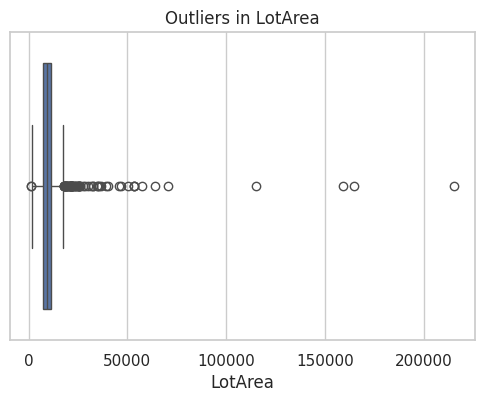

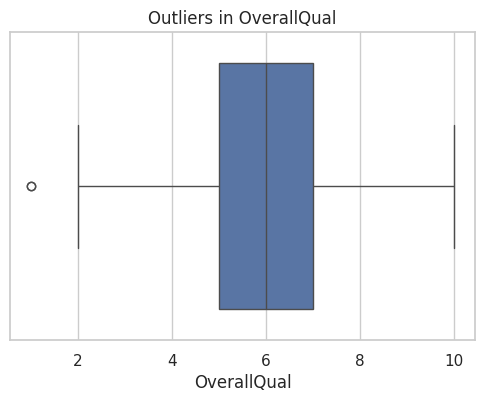

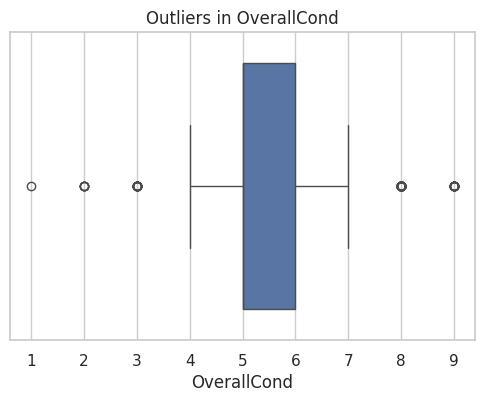

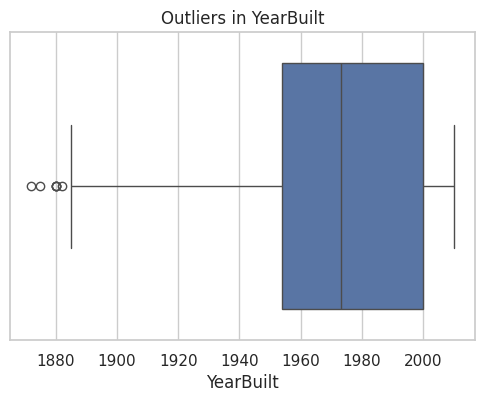

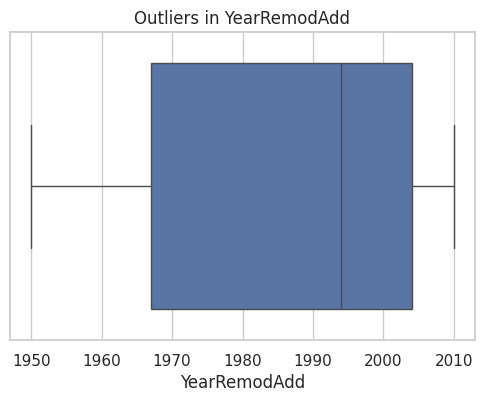

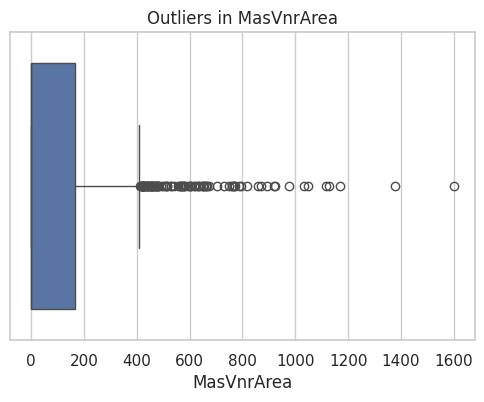

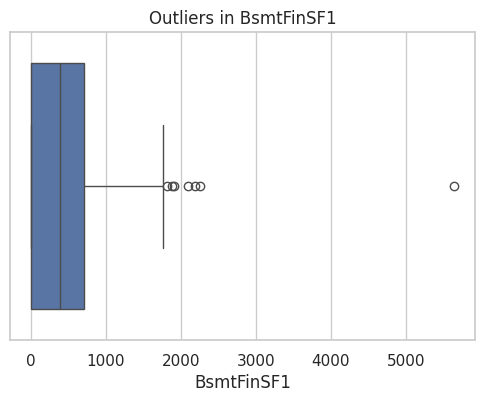

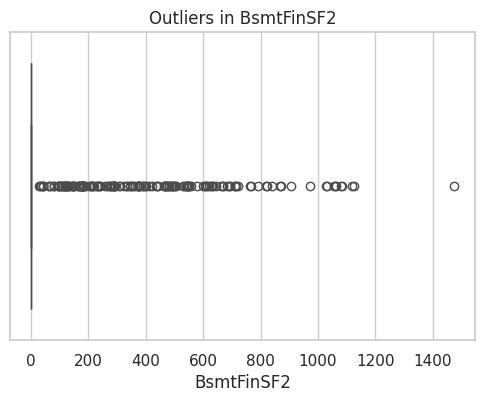

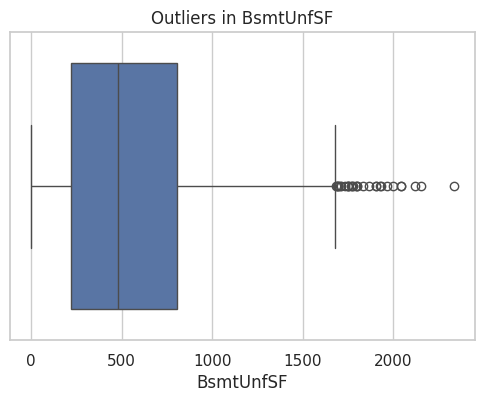

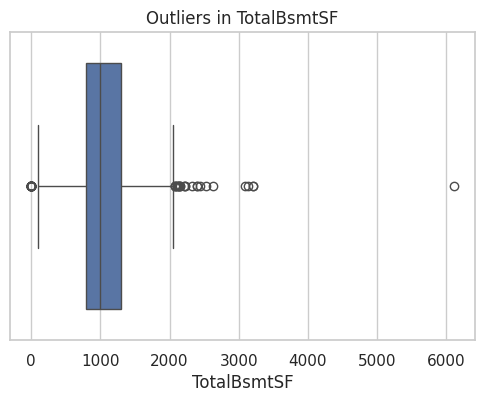

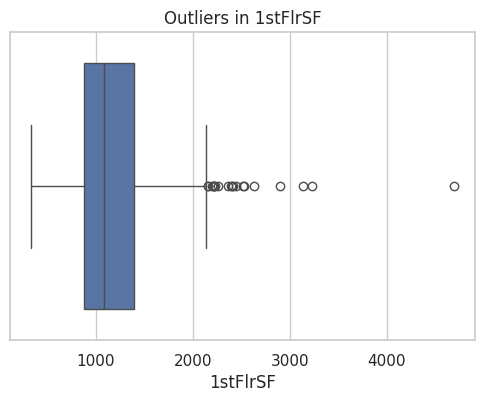

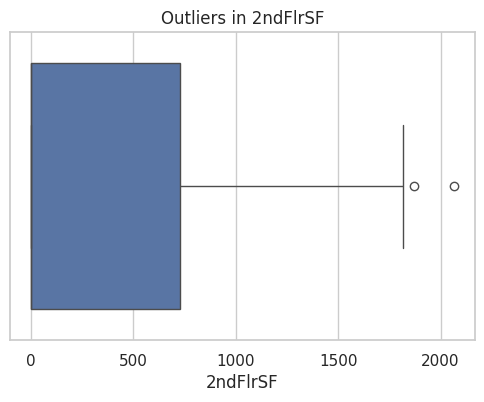

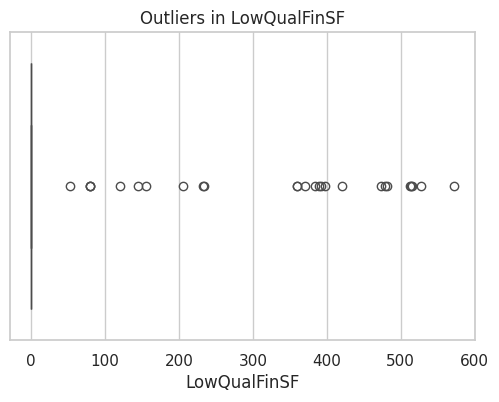

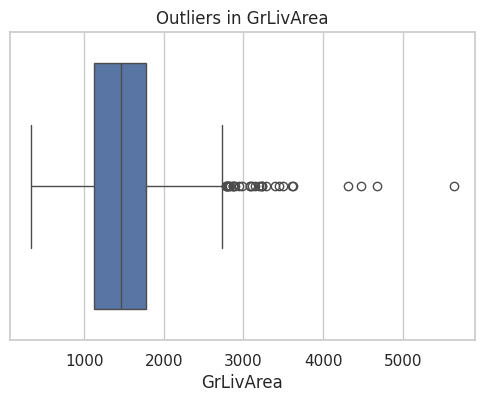

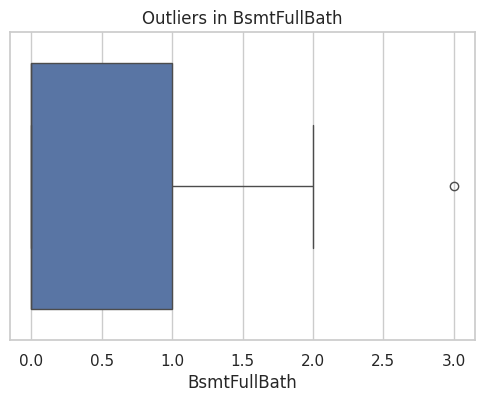

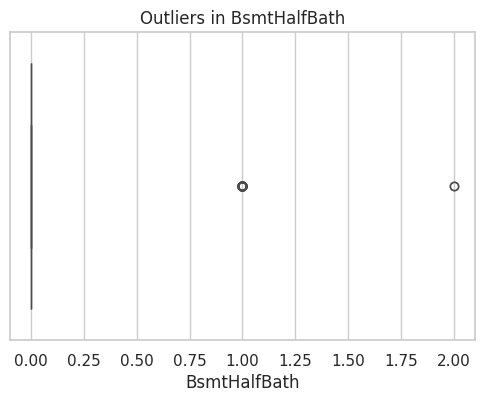

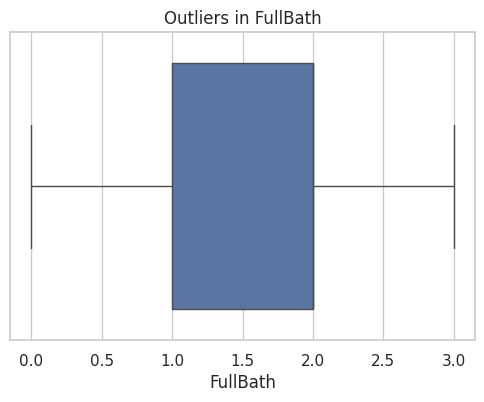

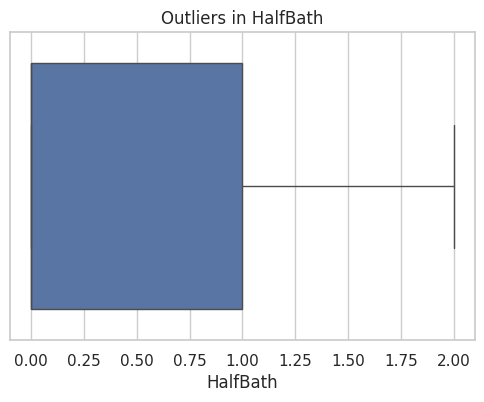

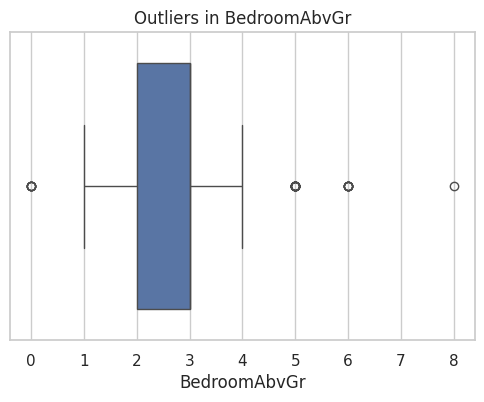

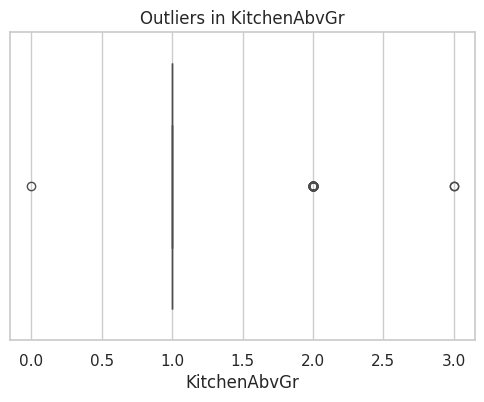

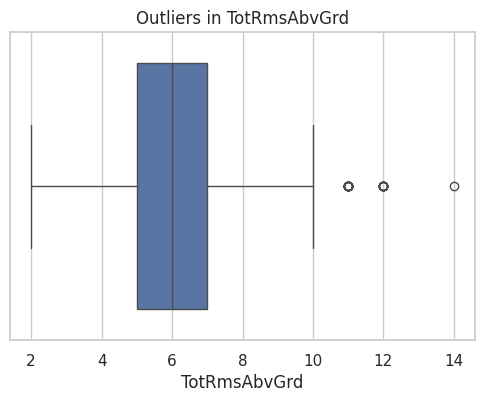

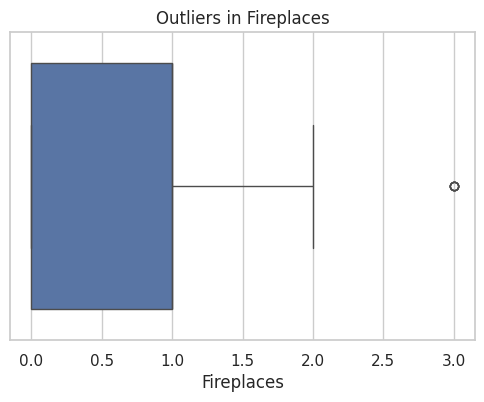

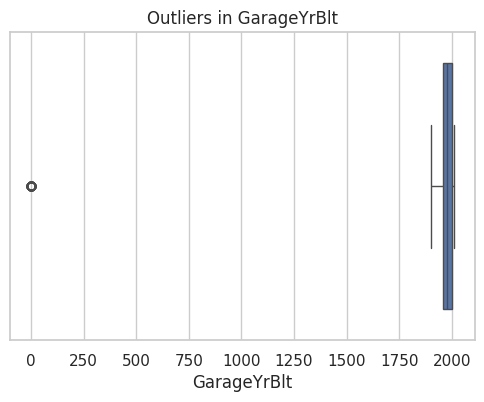

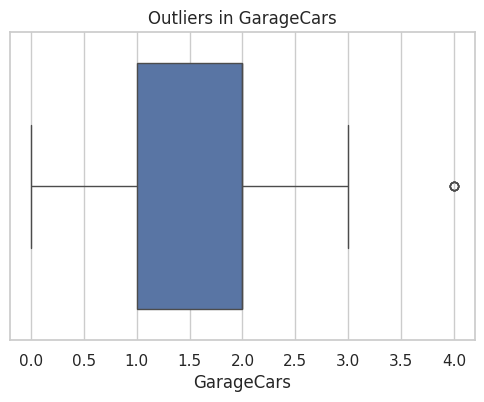

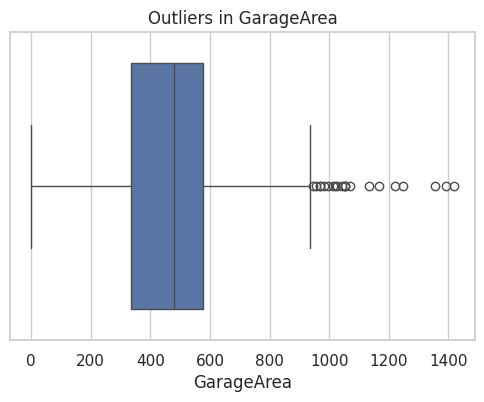

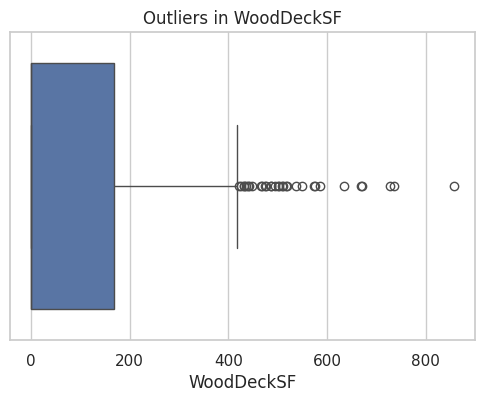

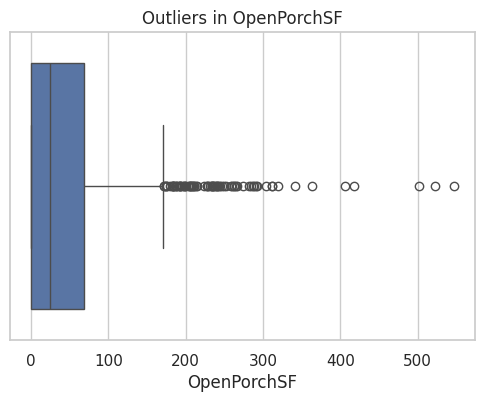

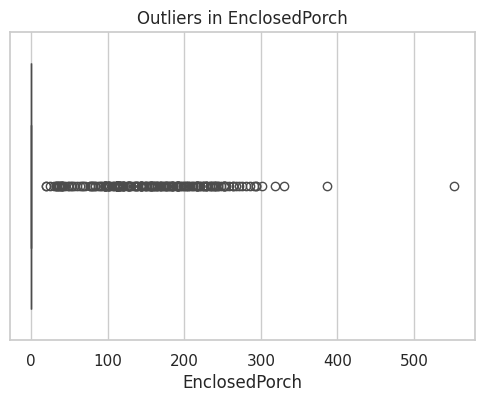

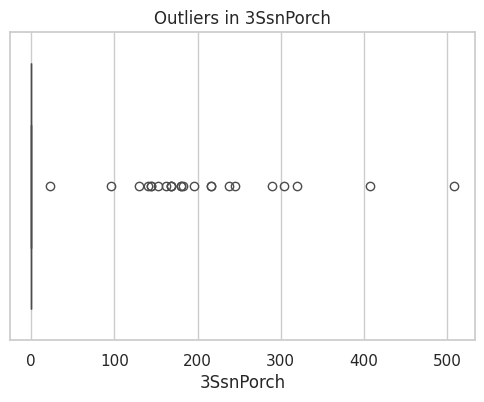

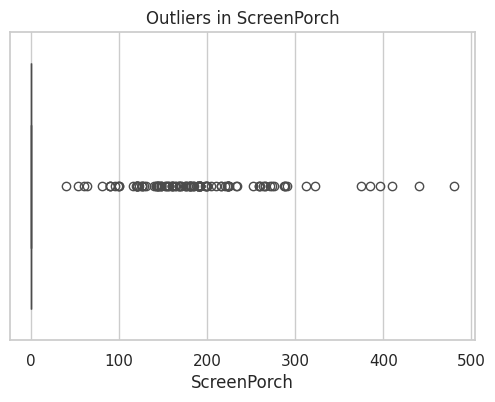

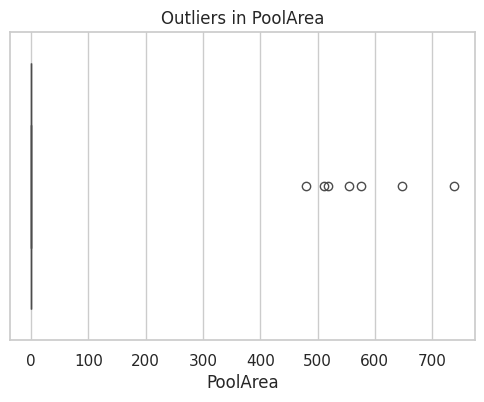

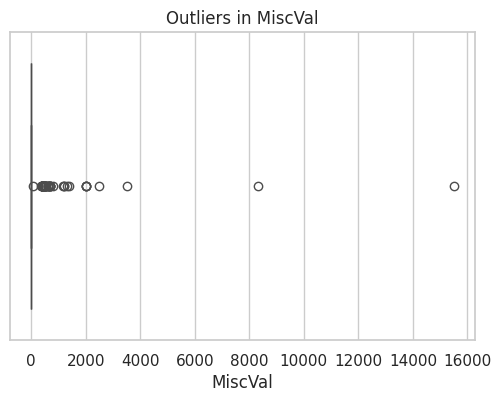

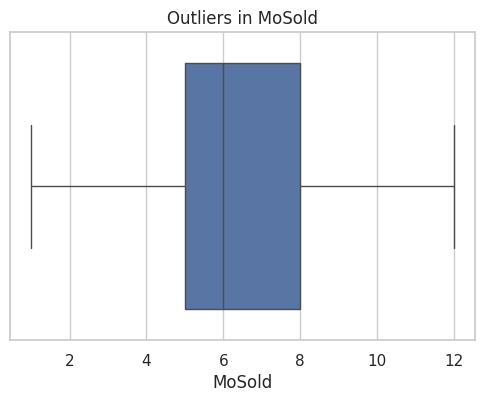

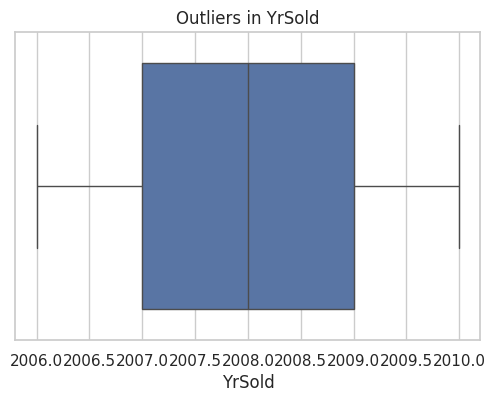

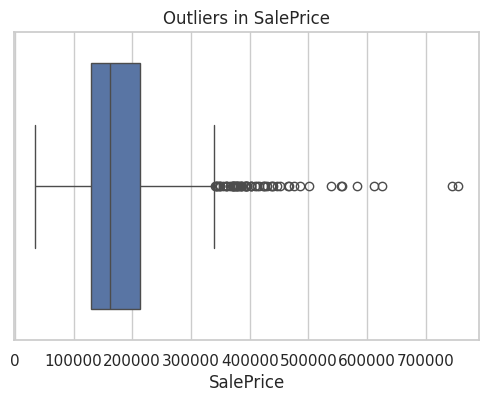

In [ ]:
for col in num_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=data[col])
    plt.title(f"Outliers in {col}")
    plt.show()

    #This code iterates through all numerical features in the dataset and creates a separate boxplot for each feature and visualizes the distribution and highlights potential outliers in that column.

IQR Method.

In [ ]:
for col in num_features:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    data[col] = np.clip(data[col], lower, upper)

print("Outliers handled using IQR clipping")

#This code handles outliers in all numerical features using the IQR (Interquartile Range) clipping method for each column.
#It calculates the first quartile Q1 and third quartile Q3.
#The IQR is computed as Q3 - Q1, representing the middle 50% of the data.
#The lower and upper bounds are defined as Q1 - 1.5*IQR and Q3 + 1.5*IQR.
#np.clip replaces any values outside these bounds with the nearest limit, effectively reducing the impact of extreme outliers without removing data points.

Outliers handled using IQR clipping


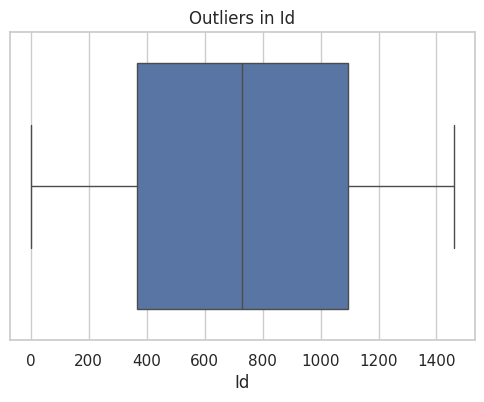

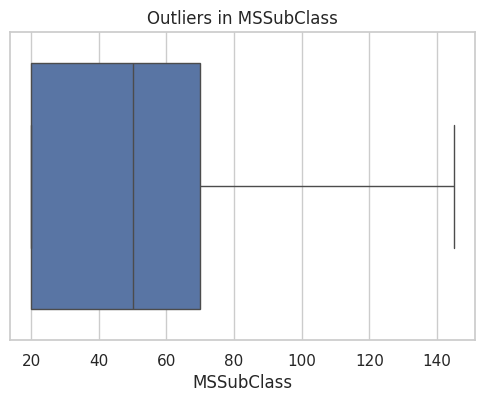

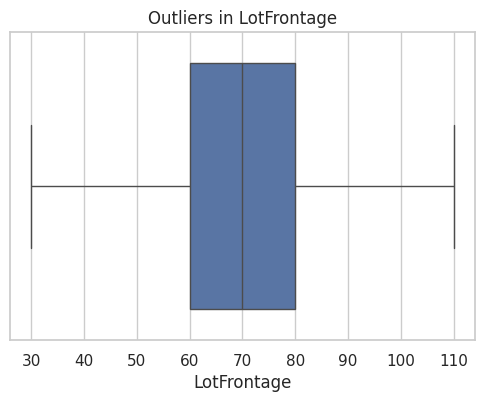

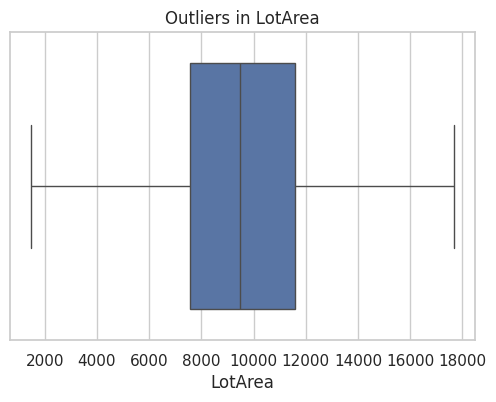

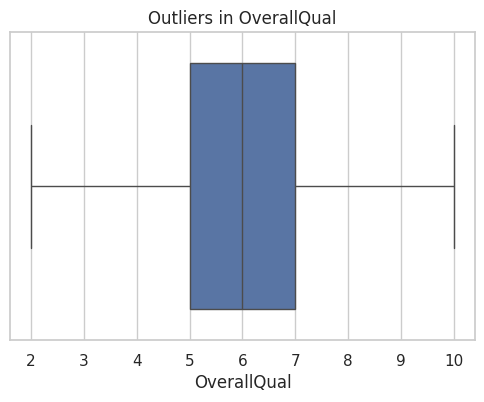

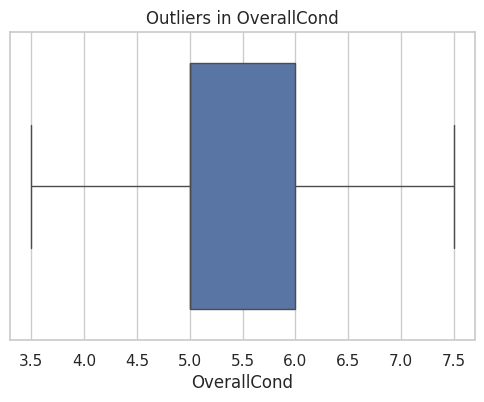

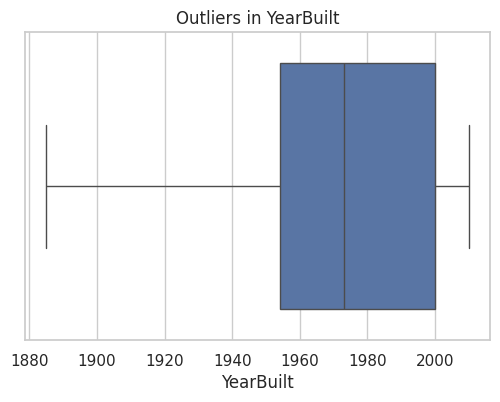

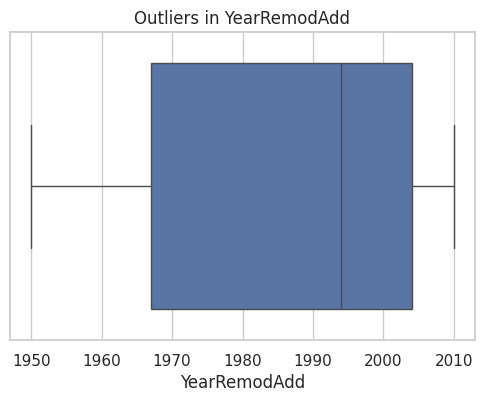

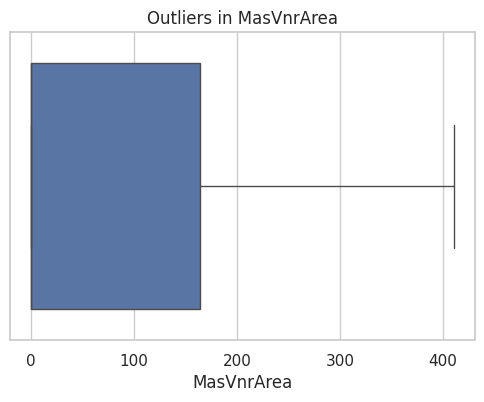

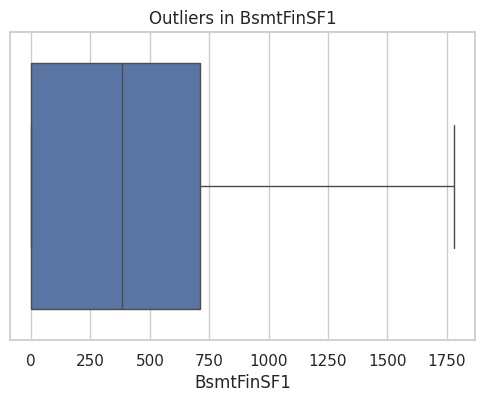

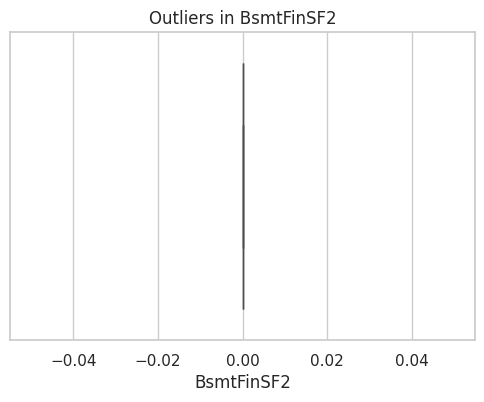

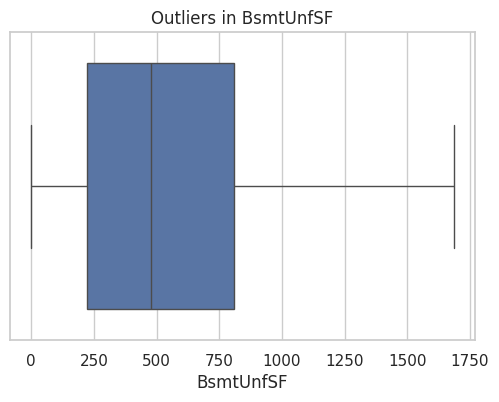

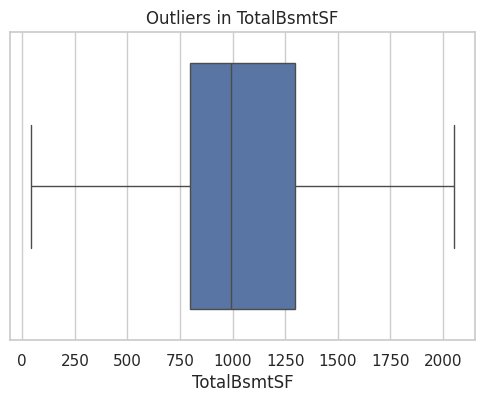

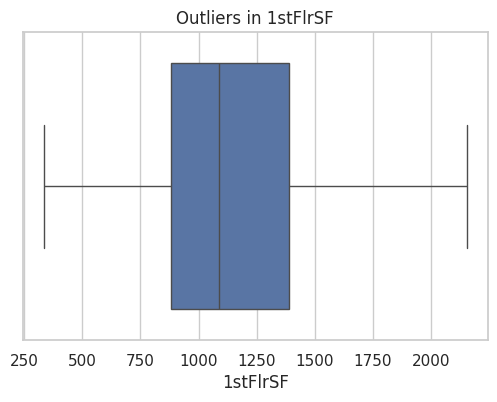

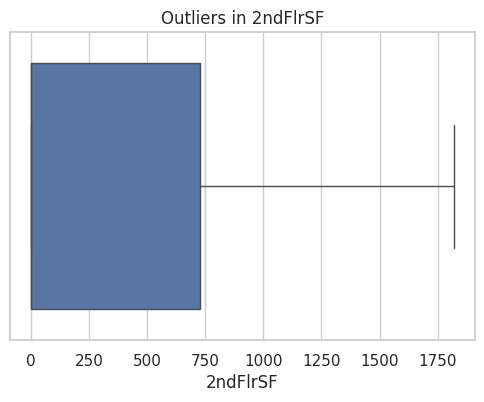

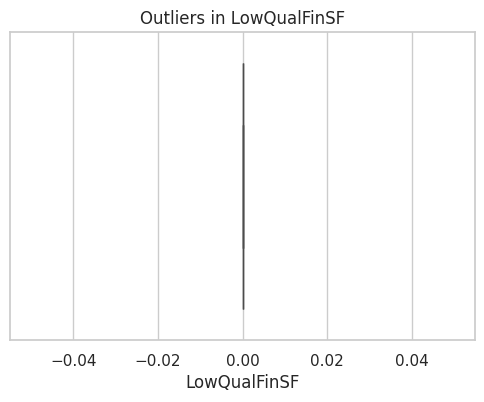

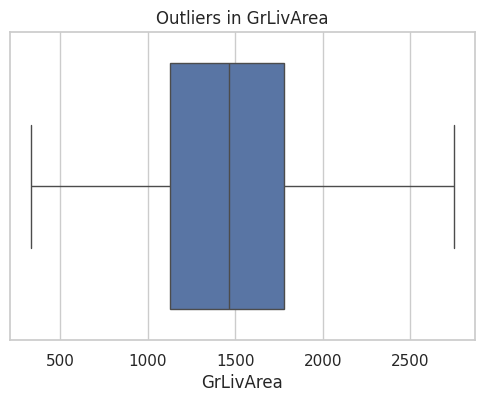

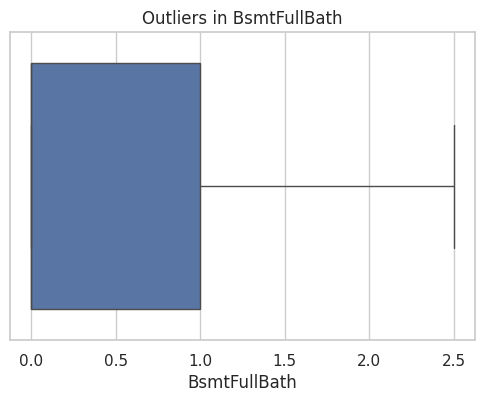

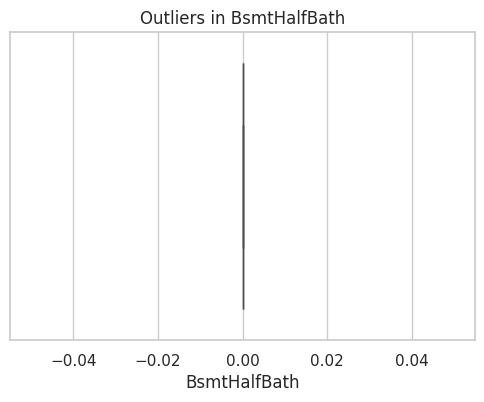

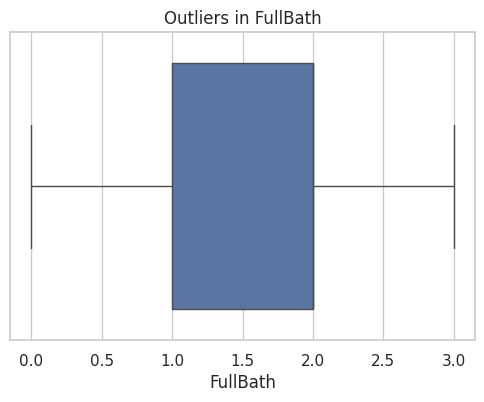

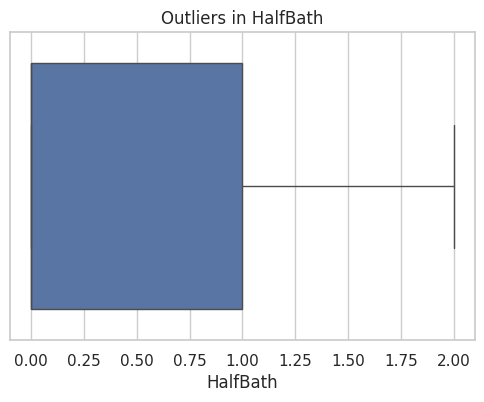

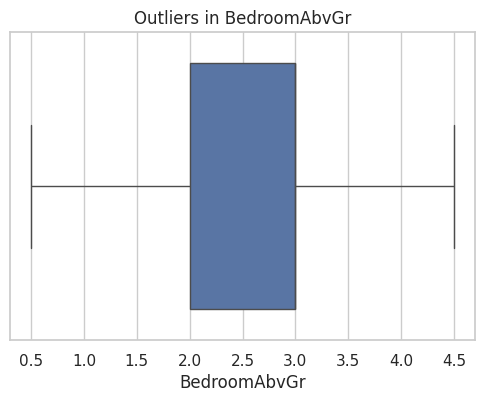

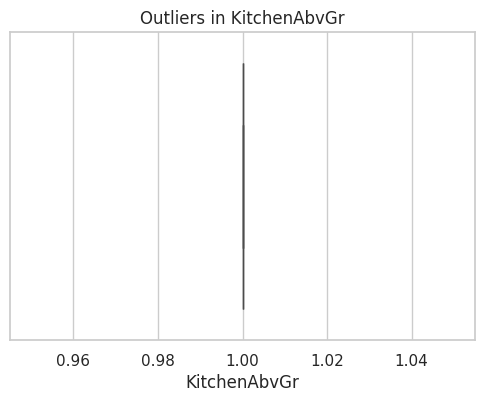

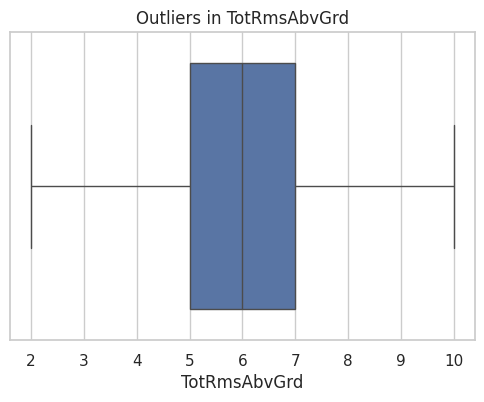

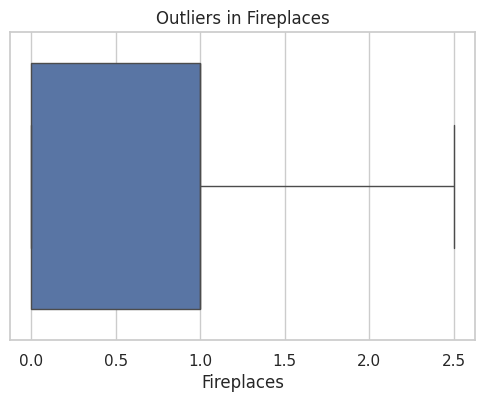

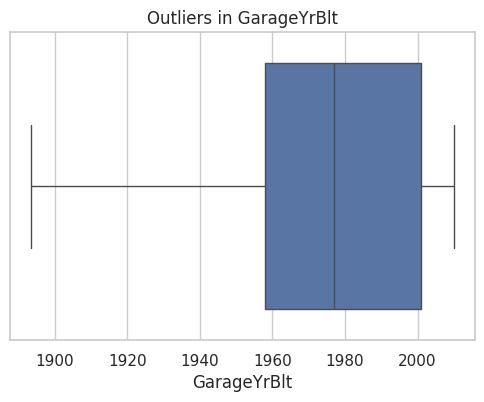

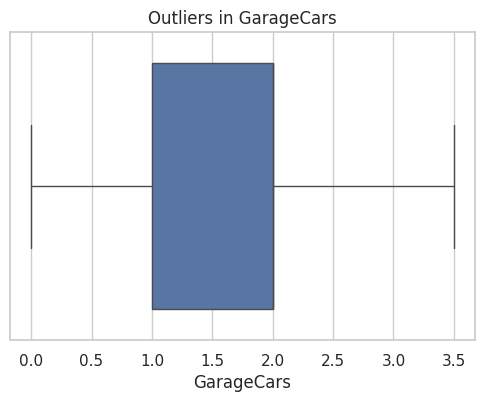

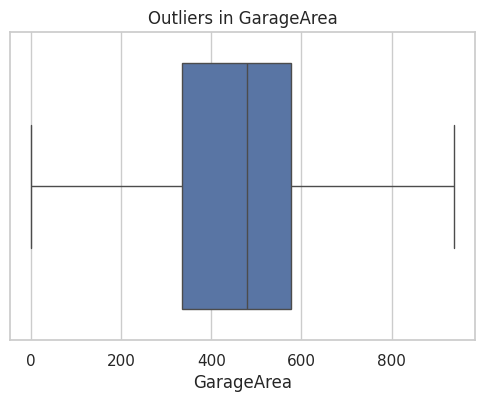

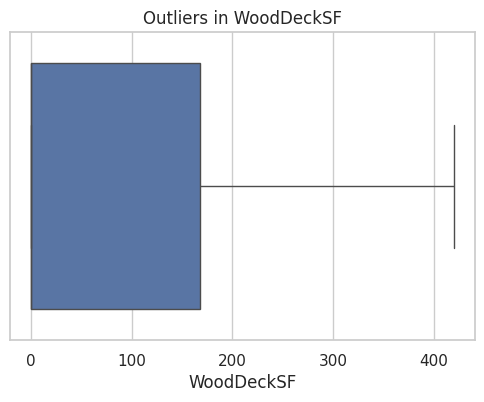

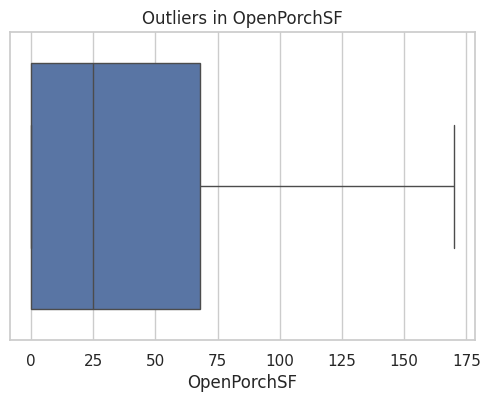

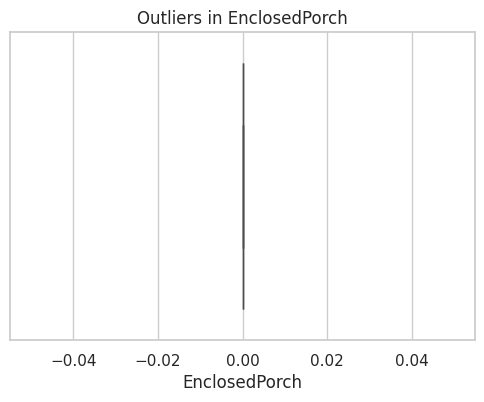

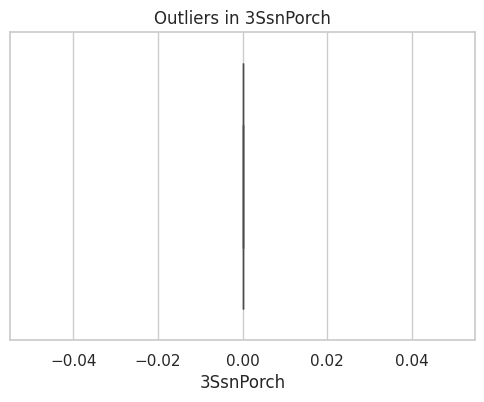

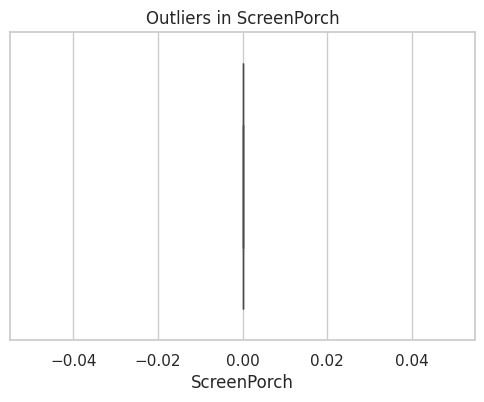

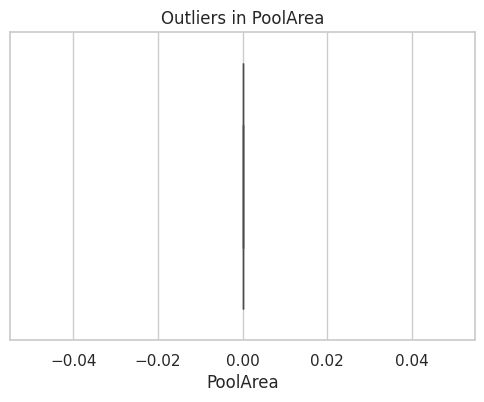

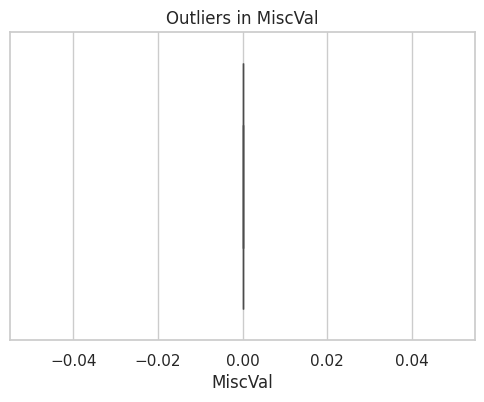

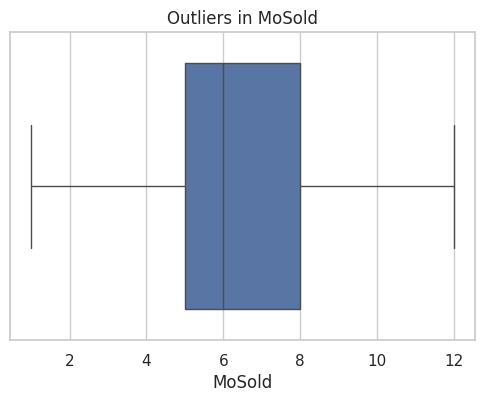

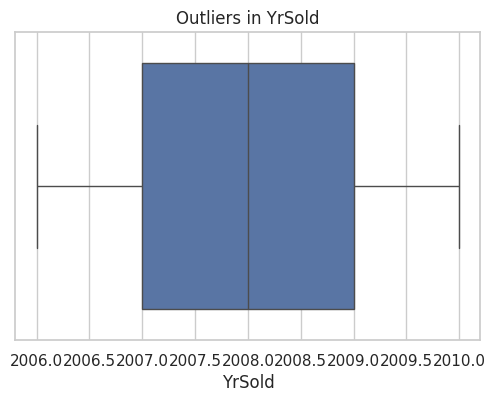

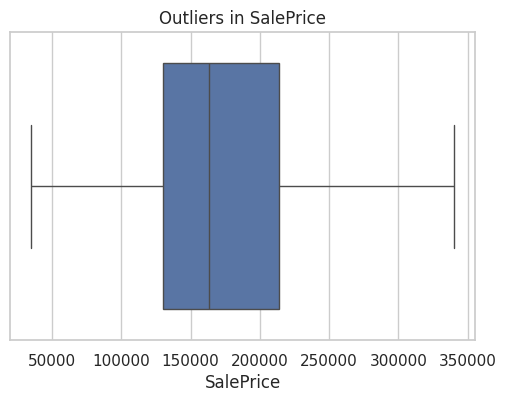

In [ ]:
for col in num_features:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=data[col])
  plt.title(f"Outliers in {col}")
  plt.show()

#This code creates a boxplot for every numerical feature.
#Boxplots help to visualize outliers by showing points that lie far from the rest of the data.
#After handling outliers these plots are used to check whether extreme values were reduced or still remain.

Scaling (After Outlier Handling)

Why scaling is needed?


Scaling is needed in data preprocessing because features in a dataset often have different ranges and units, and many machine learning algorithms are sensitive to these differences.




When scaling helps models?

Scaling helps models mainly when the algorithms calculations are sensitive to the magnitude or range of features specifically.

Gradient-based models (e.g., Linear Regression, Logistic Regression) Scaling helps the optimizer converge faster because all features contribute proportionally to the gradients.


Regularized models (e.g., Ridge, Lasso) Regularization penalizes large coefficients scaling ensures the penalty is applied fairly across all features

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[num_features])

print("Features scaled using StandardScaler")

Features scaled using StandardScaler


Categorical Columns Encoding

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])


In [ ]:
X = data.drop('SalePrice', axis=1)
y = data['SalePrice']

Train-test Split.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [ ]:
print(f"X_train sape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_tarin shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train sape: (1095, 80)
X_test shape: (365, 80)
y_tarin shape: (1095,)
y_test shape: (365,)


Linear Regression.

Which model performs better?

The model with the lower MSE value is the better model.

In most house price datasets, Linear Regression usually gets a lower MSE because

It handles continuous numerical features well

It learns the exact best fit line

It is more stable on clean structured data.


SGD Regressor:

Is an approximation of linear regression using gradient descent

May produce more error if

Learning rate isnot perfect.

Data isnot well scaled.

More iterations are needed.

Conclusion:

Linear Regression normally performs better because it computes the optimal weights directly.

SGD Regressor can perform worse if not perfectly tuned, because it depends on step by step learning.

In [ ]:
from sklearn.pipeline import Pipeline

model_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

print("Linear REgression Result:")
print(f"MSE: {mean_squared_error(y_test, y_pred_lr):.2f}")

Linear REgression Result:
MSE: 943515925.15


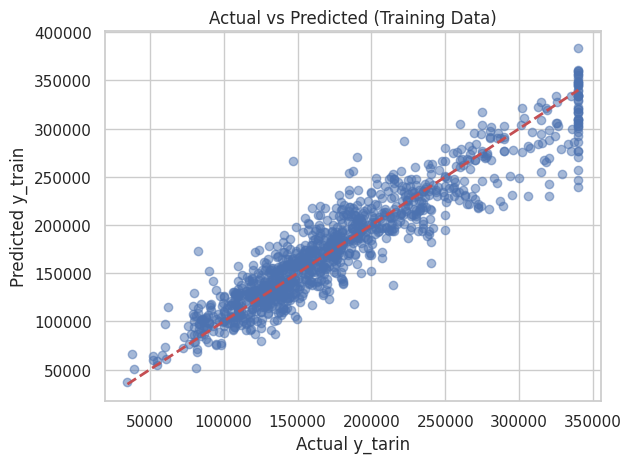

In [ ]:
y_train_pred = model_lr.predict(X_train)

plt.scatter(y_train, y_train_pred, alpha=0.5)
plt.xlabel("Actual y_tarin")
plt.ylabel("Predicted y_train")
plt.title("Actual vs Predicted (Training Data)")
plt.plot([y_train.min(), y_train.max()],
         [y_train.min(), y_train.max()],
         'r--',lw=2)
plt.show()


Check w and m.

In [ ]:
lr_estimator = model_lr.named_steps['regressor']
print("Weights (w):", lr_estimator.coef_)
print("Bias (b):", lr_estimator.intercept_)

Weights (w): [-3.10029818e+04 -2.58549756e+02  1.56446679e+04  1.04731600e+04
  5.14370358e+03 -6.65298791e+03  6.65298791e+03 -3.71259223e+03
 -5.10523699e+03  8.81782922e+03 -7.18071172e+03 -1.86588561e+03
  1.81217558e+04 -9.07515850e+03 -8.93694029e+03  7.35886794e+03
 -1.20071177e+03  2.77878413e+03  3.11376964e+04 -3.11376964e+04
  6.60673025e+03  8.08075604e+03 -8.77404316e+03 -6.80829253e+03
  8.94849398e+02 -1.03648942e+04 -2.62205882e+03  1.29869530e+04
  4.19372050e+03 -1.75622745e+04  3.01899486e+03 -1.57224602e+04
  1.12478534e+04 -9.07922752e+03  1.64577822e+04 -2.49015943e+04
 -2.01852377e+04 -2.17376865e+04 -3.81479781e+04 -1.21111471e+04
 -1.68285781e+04  1.79700712e+04 -1.78748520e+03  4.25415669e+04
  2.75033636e+04 -1.69196181e+04 -4.42981844e+03 -1.51840141e+04
 -2.79370558e+03  1.96540580e+04  3.89454248e+04  7.78553912e+02
  3.50794361e+04 -1.01597032e+04 -7.43122971e+02  7.19975424e+03
  6.48552113e+03  2.31057812e+04 -3.91333405e+03 -2.09107671e+02
 -2.55783197

SGD Regressor (Stochastic Gradient Descent Regressor).

In [ ]:
model_sgd = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', SGDRegressor())
])

model_sgd.fit(X_train, y_train)
y_pred_sgd = model_sgd.predict(X_test)
print("SGD Regressor Result:")
print(f"MSE: {mean_squared_error(y_test, y_pred_sgd):.2f}")

SGD Regressor Result:
MSE: 927536733.74


In [ ]:
sgd_estimator = model_sgd.named_steps['regressor']
print("WEights (w):", sgd_estimator.coef_)
print("Bias (b):", sgd_estimator.intercept_)

WEights (w): [ -5487.67222811   4086.04567425   9549.39702581  10138.02768583
  -4552.90153381   1724.43090859  12008.46571539   1366.25600723
   1260.57451891  11106.06609783   1501.02495231  12087.43039538
   1116.33420141   -971.89292513  -8418.43024149  11945.73446817
   5387.9042658    4817.6881315   15876.94823846  -2144.05161449
   5613.5845684   10061.07844465  -5725.04229898   1855.95083066
   1927.32507924   -659.56487298   7624.80230526   6767.6591917
  -8262.4344426   -1346.22490203   1945.3946476   -6537.98376426
   7771.17248578 -11276.97659265  19662.89849476 -19942.71297384
 -20781.59792756  -5656.40917368 -13803.63296538  -8928.84539367
 -12771.22389913    830.79719908   2795.10235686  33476.87726031
  19175.287164      342.84541752   1272.11003068 -12853.62604554
  -3162.68926016  12109.80453086  24531.43808947   2920.0829193
  12223.44336826  -6847.91320042   1038.72349009   7295.03689919
   2435.86293186   7049.90852865  -1024.13208524   4122.33403748
  -2004.024123

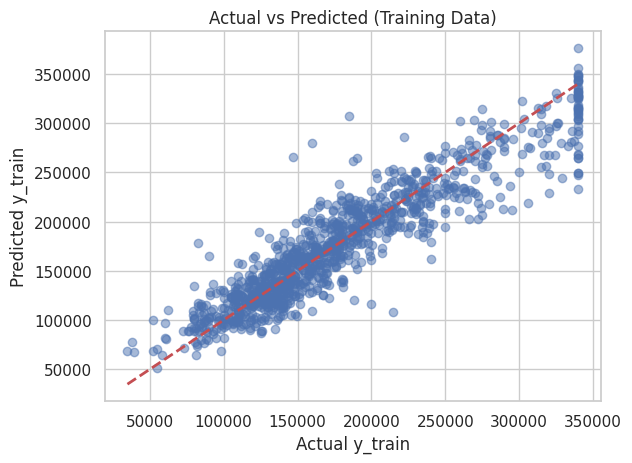

In [ ]:
y_train_pred = model_sgd.predict(X_train)

plt.scatter(y_train, y_train_pred, alpha=0.5)
plt.xlabel("Actual y_train")
plt.ylabel("Predicted y_train")
plt.title("Actual vs Predicted (Training Data)")
plt.plot([y_train.min(), y_train.max()],
         [y_train.min(), y_train.max()],
         'r--',lw=2)
plt.show()

Does house size (area) affect price?

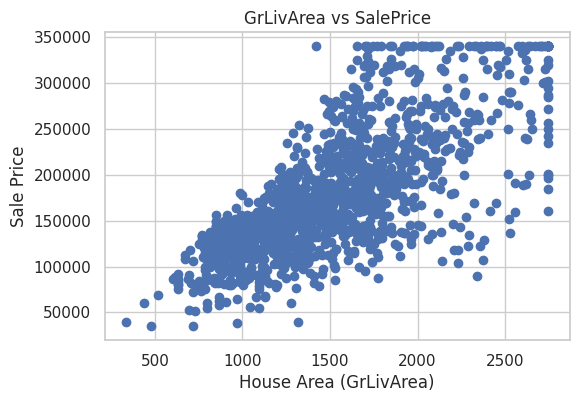

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(x='GrLivArea', y='SalePrice', data =data)
plt.xlabel("House Area (GrLivArea)")
plt.ylabel("Sale Price")
plt.title("GrLivArea vs SalePrice")
plt.show()

#This scatter plot shows the relationship between GrLivArea above-ground living area of the house and SalePrice.
#As the living area increases, the sale price also tends to increase meaning bigger houses generally sell for more money.
#The points form an upward trend, showing a positive correlation between house size and price.
#There are also some scattered points at the top or far right, which may indicate very large or very expensive houses possible outliers.


How does the number of bedrooms relate to price?

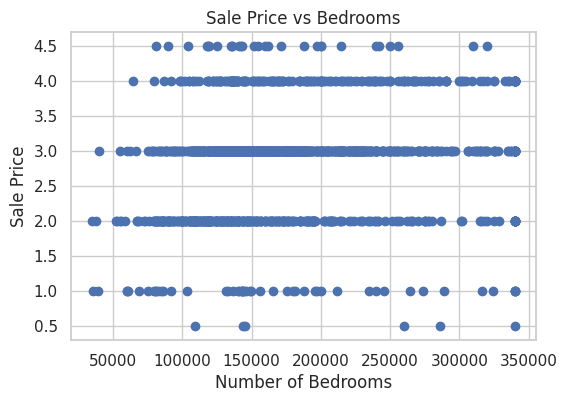

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(x='SalePrice', y='BedroomAbvGr', data= data)
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price")
plt.title("Sale Price vs Bedrooms")
plt.show()

#This scatter plot compares SalePrice with BedroomAbvGr number of bedrooms above ground.
#From the graph, there is no strong relationship between the number of bedrooms and the sale price.
#Houses with more bedrooms do not always have a higher price, and houses with fewer bedrooms can still be expensive.
#This means bedrooms alone are not a good indicator of house price, and other features like area, quality, location influence the price more.

How does location affect house price?

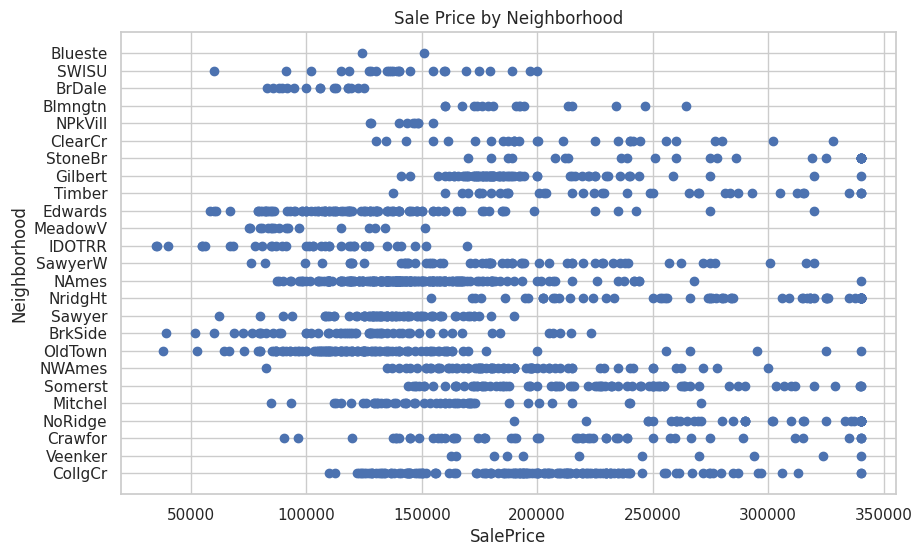

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(x='SalePrice', y='Neighborhood', data= data)
plt.xlabel("SalePrice")
plt.ylabel("Neighborhood")
plt.title("Sale Price by Neighborhood")
plt.suptitle("")   # removes extra automatic title
plt.show()

#This scatter plot shows how SalePrice varies across different neighborhoods.
#You can see that some neighborhoods have mostly higher-priced houses points clustered toward the right, while others have lower or mixed price ranges.
#This means the neighborhood has a strong influence on house prices, as certain areas consistently sell for more than others

Do houses with more bathrooms cost more?

In [ ]:
data['TotalBathrooms'] = (
    data['FullBath']
    + data['HalfBath']*0.5
    + data['BsmtFullBath']
    + data['BsmtHalfBath']*0.5
)

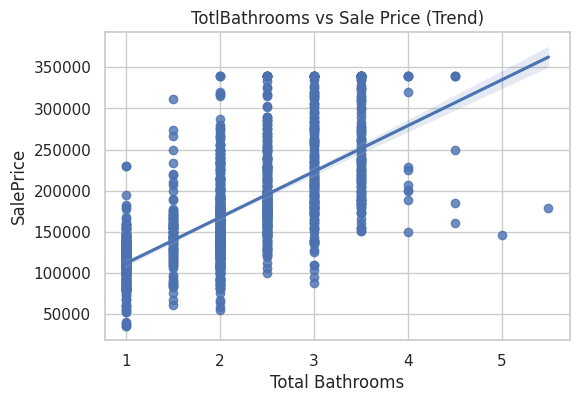

In [ ]:
plt.figure(figsize=(6,4))
sns.regplot(x='TotalBathrooms', y='SalePrice', data=data)
plt.title("TotlBathrooms vs Sale Price (Trend)")
plt.xlabel("Total Bathrooms")
plt.ylabel("SalePrice")
plt.show()

#This regression plot shows the relationship between TotalBathrooms and SalePrice.
#As the number of bathrooms increases, the sale price also tends to increase showing a positive trend.
#The regression line indicates that houses with more bathrooms generally sell for higher prices, although there is still some variation among individual houses.

Which feature has the strongest correlation with SalePrice?

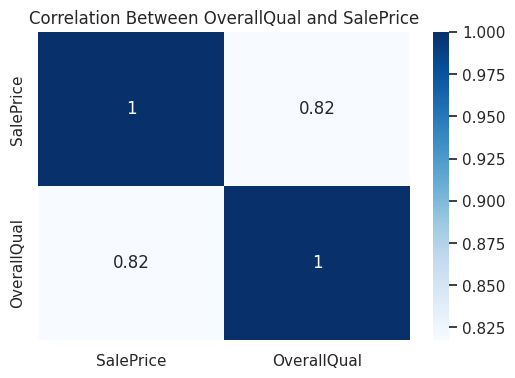

In [ ]:
plt.figure(figsize=(6,4))
sns.heatmap(data[['SalePrice', 'OverallQual']].corr(), annot=True, cmap="Blues")
plt.title("Correlation Between OverallQual and SalePrice")
plt.show()


#This heatmap shows the correlation between OverallQual overall quality of the house and SalePrice.
#The value 0.82 means there is a strong positive correlation.
#As OverallQual increases, the SalePrice also increases.
#Darker blue color shows a strong relationship.
#The values 1 on the diagonal mean a feature is perfectly correlated with itself normal.

Conclusion:




Factors That Most Impact House Prices.

OverallQual overall material & finish quality showed one of the strongest positive correlations with SalePrice.

TotalBathrooms, GrLivArea above ground living area, GarageCars, and YearBuilt also strongly influenced prices.


Certain neighborhoods such as StoneBr, NridgHt, and NoRidge consistently had higher priced homes.


Which variables needed cleaning.

Multiple categorical features like PoolQC, Alley, Fence, FireplaceQu, etc had large missing values that correctly represented No feature, so assigning None was appropriate.

LotFrontage had many missing values and was best filled using median by Neighborhood, improving consistency.

Garage related and Basement related variables with missing values were logically replaced with 0 or None.

After cleaning, the dataset contained no missing values, improving model stability.

Any strong correlations found.

OverallQual, GrLivArea, and TotalBathrooms showed strong positive correlations with SalePrice.

YearBuilt and GarageCars also showed meaningful correlations.

Very weak or no correlation was observed with variables like LowQualFinSF, MiscVal, and PoolArea mostly zeros.

Observations from visual trends.


Scatterplots showed clear upward trends between GrLivArea, TotalBathrooms, and SalePrice, indicating that larger and better equipped homes cost more.

Neighborhood wise scatterplots revealed that some locations consistently sell at premium prices.

Boxplots identified outliers in features such as LotArea, SalePrice, and GrLivArea, which were successfully handled using IQR clipping.

Which model performed better.


Linear Regression performed well after:

Handling missing values

Removing/healing outliers

Scaling numerical variables

One-hot encoding categorical features

The model captured the general trend of house prices, as seen in the Actual vs Predicted plot.

The preprocessing pipeline ColumnTransformer + Pipeline ensured clean, reproducible results.